# Práctica 2: Visualización de Juego de Tronos

| | |
|---|---|
| **Grupo** | G-7311 |
| **Pareja** | P06 |
| **Miembros** | Jorge Rodríguez, Marc Martínez, Juan Fernández |

**Asignatura:** Visualización de Datos · Grado en Ciencia e Ingeniería de Datos (UAM)

### Contenido
- **Parte 1 – Grafos con NetworkX:** 1.1 Construcción del grafo · 1.2 Centralidad · 1.3 Subredes y comunidades
- **Parte 2 – Mapas con Folium:** 2.1 Mapa base · 2.2 Importancia de cada ubicación · 2.3 Ruta de un episodio
- **Parte 3 (opcional) – PyVis:** 3.1 Física del grafo · 3.2 Interacción enriquecida

### Datos y estructura de carpetas
El notebook espera encontrar, en la misma carpeta en la que se ejecuta:
- `game_of_thrones/data/` (o `data/`): JSON del repositorio *game-of-thrones-data* (`characters.json`, `episodes.json`, …).
- `GOT-Map/land.geojson` y `GOT-Map/places.geojson`: formas del territorio y lugares.
- `places.geojson.json`: versión ampliada de `places.geojson` que, además de ciudades y castillos, incluye las **regiones y mares** (*The North*, *The Crownlands*, *The Narrow Sea*, …). Es la que permite enlazar el campo `location` de las escenas con coordenadas.

Si las carpetas no existen pero están los ZIP originales, la primera celda de código los descomprime automáticamente.
Las figuras de las partes 1 y 2 se exportan a PDF en `graficos/`. La parte 2 también guarda mapas interactivos en HTML y la parte 3 guarda dos grafos interactivos en HTML.

## 0. Configuración del entorno

La práctica se ha verificado con **Python 3.12**. Si es necesario recrear el entorno, ejecuta estos comandos en una terminal desde la carpeta del notebook.

```bash
python3.12 -m venv .venv
./.venv/bin/python -m pip install ipykernel numpy pandas scipy networkx matplotlib folium branca pyvis
```

En VS Code selecciona `.venv/bin/python` como kernel, reinícialo y pulsa **Ejecutar todo**. `ipykernel` permite usar el entorno desde VS Code y `scipy` se usa en los layouts y PageRank de NetworkX. `pyvis` solo se necesita para la parte 3. Los PDF se generan directamente con Matplotlib. Los HTML interactivos usan bibliotecas JavaScript remotas y requieren conexión al abrirlos.

In [1]:
import json
import math
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import folium
from folium import plugins
import branca.colormap as bcm
from branca.element import Element
from IPython.display import display, IFrame

BASE = Path.cwd()


def localizar_datos():
    """Devuelve la carpeta con los JSON del dataset; descomprime el ZIP si hace falta."""
    for cand in (BASE / "game_of_thrones" / "data", BASE / "data"):
        if all((cand / fichero).is_file() for fichero in ("characters.json", "episodes.json")):
            return cand
    zips = sorted(BASE.glob("game_of_thrones*.zip")) + sorted(BASE.glob("GOT-Data*.zip"))
    if not zips:
        raise FileNotFoundError("No se encuentran los datos de game_of_thrones")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall(BASE / "game_of_thrones")
    return BASE / "game_of_thrones" / "data"


def localizar_mapas():
    """Devuelve la carpeta con land.geojson; descomprime el ZIP si hace falta."""
    carpeta = BASE / "GOT-Map"
    if not (carpeta / "land.geojson").exists():
        zips = sorted(BASE.glob("GOT-Map*.zip")) + sorted(BASE.glob("GOT-Maps*.zip"))
        if not zips:
            raise FileNotFoundError("No se encuentran los GeoJSON de GOT-Map")
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(BASE)
    return carpeta


DATA_DIR = localizar_datos()
MAP_DIR = localizar_mapas()

# Carpetas de salida (gráficos exportados a PDF / HTML)
GRAF_DIR = BASE / "graficos"
DIR_P1 = GRAF_DIR / "parte1_networkx"
DIR_P2 = GRAF_DIR / "parte2_folium"
DIR_P3 = GRAF_DIR / "parte3_pyvis_opcional"
for d in (DIR_P1, DIR_P2, DIR_P3):
    d.mkdir(parents=True, exist_ok=True)

# Estilo general de las figuras
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 200,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def guardar_figura(fig, nombre, carpeta=DIR_P1):
    """Exporta una figura de Matplotlib a PDF."""
    ruta = carpeta / f"{nombre}.pdf"
    fig.savefig(ruta, bbox_inches="tight")
    return ruta


def exportar_mapa(mapa, nombre, fig):
    """Guarda el mapa interactivo en HTML y su versión estática en PDF."""
    mapa.save(str(DIR_P2 / f"{nombre}.html"))
    guardar_figura(fig, nombre, DIR_P2)
    plt.close(fig)
    print(f"Mapa exportado: {nombre}.html y {nombre}.pdf")


print("Datos:", DATA_DIR.relative_to(BASE), "| Mapas:", MAP_DIR.relative_to(BASE))
print("Versiones -> networkx", nx.__version__, "| matplotlib", mpl.__version__, "| folium", folium.__version__)

Datos: game_of_thrones/data | Mapas: GOT-Map
Versiones -> networkx 3.7 | matplotlib 3.11.2 | folium 1.0.0


# Parte 1: Visualización de grafos con NetworkX

## Apartado 1.1: Construcción del grafo de relaciones
### 1. Carga y exploración de los datos
Primero cargamos el JSON. Como hemos comprobado, los personajes están dentro de la clave `characters` y sus nombres se almacenan en `characterName`. El resto de claves son, o bien información descriptiva (actor, imagen, casa…), o bien **listas de nombres de otros personajes**, que son las relaciones. Usamos el nombre como identificador, por lo que los 389 registros se reducen a 370 nodos. Esto reúne entradas homónimas como `White Walker` y limita la interpretación de esos nodos. Exploramos cuántas relaciones hay de cada tipo y cuántas apuntan a personajes que existen en el propio dataset (las que no, no se pueden convertir en aristas).

In [2]:
with open(DATA_DIR / "characters.json", encoding="utf-8") as f:
    characters = json.load(f)["characters"]

nombres = {c["characterName"] for c in characters}

# Campos que no son relaciones entre personajes
CAMPOS_DESCRIPTIVOS = {"characterName", "characterLink", "actorName", "actorLink", "characterImageThumb",
                       "characterImageFull", "houseName", "royal", "actors", "nickname", "kingsguard"}

filas = []
for campo in sorted({k for c in characters for k in c} - CAMPOS_DESCRIPTIVOS):
    destinos = [v for c in characters for v in c.get(campo, [])]
    filas.append({
        "campo": campo,
        "personajes con el campo": sum(campo in c for c in characters),
        "relaciones": len(destinos),
        "destino en el dataset": sum(v in nombres for v in destinos),
    })

df_campos = pd.DataFrame(filas).sort_values("relaciones", ascending=False).reset_index(drop=True)
print(f"Personajes en el fichero: {len(characters)} ({len(nombres)} nombres únicos)")
df_campos

Personajes en el fichero: 389 (370 nombres únicos)


,campo,personajes con el campo,relaciones,destino en el dataset
0,killed,80,222,170
1,killedBy,190,206,178
2,siblings,56,134,133
3,parents,56,81,81
4,parentOf,37,78,76
5,marriedEngaged,43,55,55
6,serves,15,22,22
7,guardianOf,12,15,15
8,guardedBy,9,12,12
9,servedBy,4,10,10


### 2. Selección de relaciones y dirección
Muchos campos son **la misma relación vista desde los dos extremos** (`parents`/`parentOf`, `killed`/`killedBy`, `serves`/`servedBy`), por lo que los fusionamos en un único tipo y eliminamos duplicados. `sibling` es una errata de `siblings`. Descartamos `guardianOf`/`guardedBy` y `abducted` por tener muy pocas relaciones y una semántica ambigua.

Seleccionamos **seis tipos de relación** que cubren familia, conflicto y lealtad:

| Tipo | Campos fusionados | ¿Dirigida? | Sentido de la arista | Motivo |
|---|---|---|---|---|
| **Parentesco** | `parents`, `parentOf` | Sí | padre/madre → hijo/a | La relación es asimétrica (genealogía). |
| **Hermanos** | `siblings`, `sibling` | No | — | Es simétrica: si A es hermano de B, B lo es de A. |
| **Matrimonio** | `marriedEngaged` | No | — | Simétrica. |
| **Asesinato** | `killed`, `killedBy` | Sí | asesino → víctima | Es la relación de conflicto más rica del dataset y es claramente asimétrica. |
| **Servicio** | `serves`, `servedBy` | Sí | sirviente → señor | Asimétrica (lealtad jerárquica). |
| **Alianza** | `allies` | No | — | Simétrica. Tiene muy pocas relaciones, pero la mantenemos porque el enunciado la sugiere. |

Por tanto, el grafo es **mixto**: lo implementamos como `MultiDiGraph` (permite varias relaciones distintas entre el mismo par de personajes, por ejemplo hermanos y asesinato) y cada arista guarda los atributos `relation` (tipo) y `directed` (si la dirección tiene significado). Las relaciones no dirigidas se guardan **una sola vez** por pareja, para que no cuenten doble en el grado.

In [3]:
# campo del JSON -> (tipo de relación, ¿dirigida?, ¿invertir sentido?)
# "invertir" indica que el personaje del registro es el DESTINO de la arista
# (p. ej. en killedBy el registro es la víctima y la arista va asesino -> víctima).
RELACIONES = {
    "parents":        ("parentesco", True,  True),
    "parentOf":       ("parentesco", True,  False),
    "siblings":       ("hermanos",   False, False),
    "sibling":        ("hermanos",   False, False),
    "marriedEngaged": ("matrimonio", False, False),
    "killedBy":       ("asesinato",  True,  True),
    "killed":         ("asesinato",  True,  False),
    "serves":         ("servicio",   True,  False),
    "servedBy":       ("servicio",   True,  True),
    "allies":         ("alianza",    False, False),
}
TIPOS = ["parentesco", "hermanos", "matrimonio", "asesinato", "servicio", "alianza"]


def casa_principal(personaje):
    """Primera casa del personaje (houseName puede ser texto o lista)."""
    casa = personaje.get("houseName")
    if isinstance(casa, list):
        casa = casa[0] if casa else None
    return casa


def construir_grafo(personajes, relaciones):
    G = nx.MultiDiGraph()
    for p in personajes:
        G.add_node(p["characterName"], house=casa_principal(p) or "Sin casa", royal=bool(p.get("royal")))

    vistas = set()
    for p in personajes:
        a = p["characterName"]
        for campo, (tipo, dirigida, invertir) in relaciones.items():
            for b in p.get(campo, []):
                if b not in nombres or b == a:          # destino desconocido o bucle
                    continue
                u, v = (b, a) if invertir else (a, b)
                clave = (tipo, u, v) if dirigida else (tipo, *sorted((u, v)))
                if clave in vistas:                    # relación ya añadida desde el otro extremo
                    continue
                vistas.add(clave)
                G.add_edge(u, v, relation=tipo, directed=dirigida)
    return G


G = construir_grafo(characters, RELACIONES)

aislados = list(nx.isolates(G))
print("Número de personajes (nodos):", G.number_of_nodes())
print("Número de relaciones (aristas):", G.number_of_edges())
print("Personajes sin ninguna relación seleccionada:", len(aislados))
pd.Series(Counter(d["relation"] for *_, d in G.edges(data=True))).reindex(TIPOS).rename("aristas").to_frame().T

Número de personajes (nodos): 370
Número de relaciones (aristas): 384
Personajes sin ninguna relación seleccionada: 151


,parentesco,hermanos,matrimonio,asesinato,servicio,alianza
aristas,82,71,28,176,23,4


### 3. Elección del layout
Antes de la visualización final comparamos los dos layouts basados en fuerzas más habituales sobre el grafo de personajes con alguna relación: `spring_layout` (Fruchterman-Reingold) y `kamada_kawai_layout` (intenta que la distancia en el plano sea proporcional a la distancia en el grafo). Los layouts circular o aleatorio se descartan porque no agrupan a los personajes relacionados.

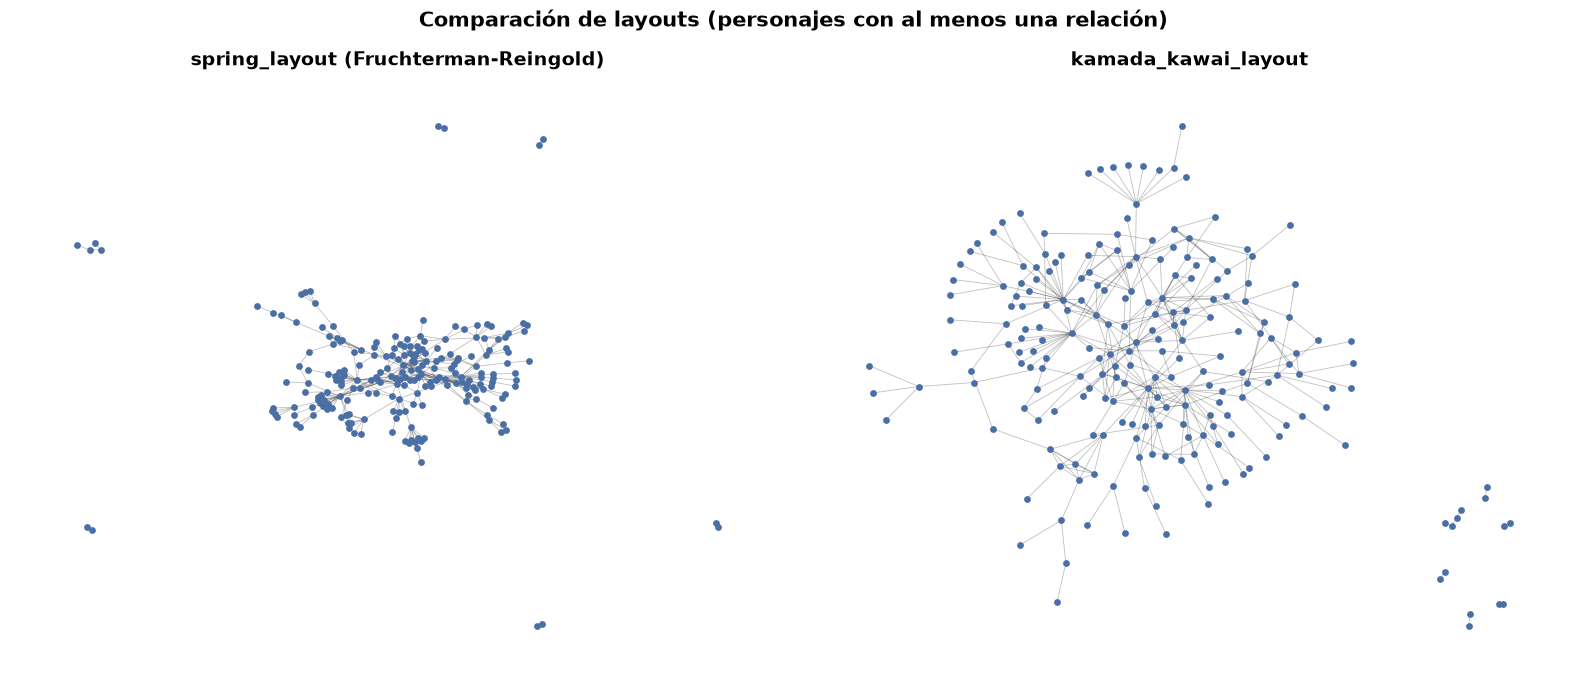

In [4]:
# Grafo no dirigido y simple, solo con los personajes que tienen alguna relación
G_rel = G.copy()
G_rel.remove_nodes_from(aislados)
G_und = nx.Graph(G_rel)


def layout_por_componentes(H, seed=42):
    """Kamada-Kawai para la componente gigante y spring para el resto, colocado alrededor."""
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    pos = nx.kamada_kawai_layout(H.subgraph(comps[0]))
    resto = H.subgraph(set().union(*comps[1:])) if len(comps) > 1 else nx.Graph()
    if resto.number_of_nodes():
        pos_resto = nx.spring_layout(resto, seed=seed, k=0.3)
        for n, (x, y) in pos_resto.items():
            pos[n] = np.array([1.12 + 0.12 * x, -0.8 + 0.3 * y])
    return pos


pos_spring = nx.spring_layout(G_und, seed=42, k=0.18, iterations=200)
pos_kk = layout_por_componentes(G_und)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (titulo, pos) in zip(axes, [("spring_layout (Fruchterman-Reingold)", pos_spring),
                                     ("kamada_kawai_layout", pos_kk)]):
    nx.draw_networkx_edges(G_und, pos, ax=ax, alpha=0.25, width=0.6)
    nx.draw_networkx_nodes(G_und, pos, ax=ax, node_size=15, node_color="#4a6fa5")
    ax.set_title(titulo)
    ax.axis("off")
fig.suptitle("Comparación de layouts (personajes con al menos una relación)", fontsize=15, fontweight="bold")
plt.tight_layout()
guardar_figura(fig, "1_1a_comparacion_layouts")
plt.show()

Con `spring_layout` las componentes pequeñas y los nodos poco conectados se dispersan por toda la figura y el núcleo queda muy compacto. `kamada_kawai_layout` reparte mejor la componente gigante (205 personajes) y respeta las distancias del grafo: las familias quedan como "racimos" reconocibles y los personajes puente entre ellas quedan entre los racimos. Por eso usamos Kamada-Kawai para la componente gigante y colocamos las pequeñas componentes sueltas en un lateral.

### 4. Visualización del grafo completo
Decisiones de diseño:
- **Aristas:** color por tipo de relación con la paleta *Okabe-Ito* (apta para daltónicos). Las relaciones **dirigidas** se dibujan con línea continua y punta de flecha; las **no dirigidas**, con línea discontinua y sin flecha. Así la dirección se codifica dos veces (estilo y flecha).
- **Tamaño del nodo:** proporcional al **grado** (número total de relaciones de cada personaje).
- **Color del nodo:** casa noble a la que pertenece (las 8 casas con más personajes); el resto en gris claro. Así se comprueba a simple vista si las relaciones se producen dentro o entre casas.
- **Etiquetas:** solo los 25 personajes de mayor grado, con un fondo blanco semitransparente. La vista de detalle conserva todas las relaciones. Una vista general adicional incorpora también los 151 personajes aislados en un panel separado.

La vista de detalle omite los 151 aislados, que se incluyen en la vista general.


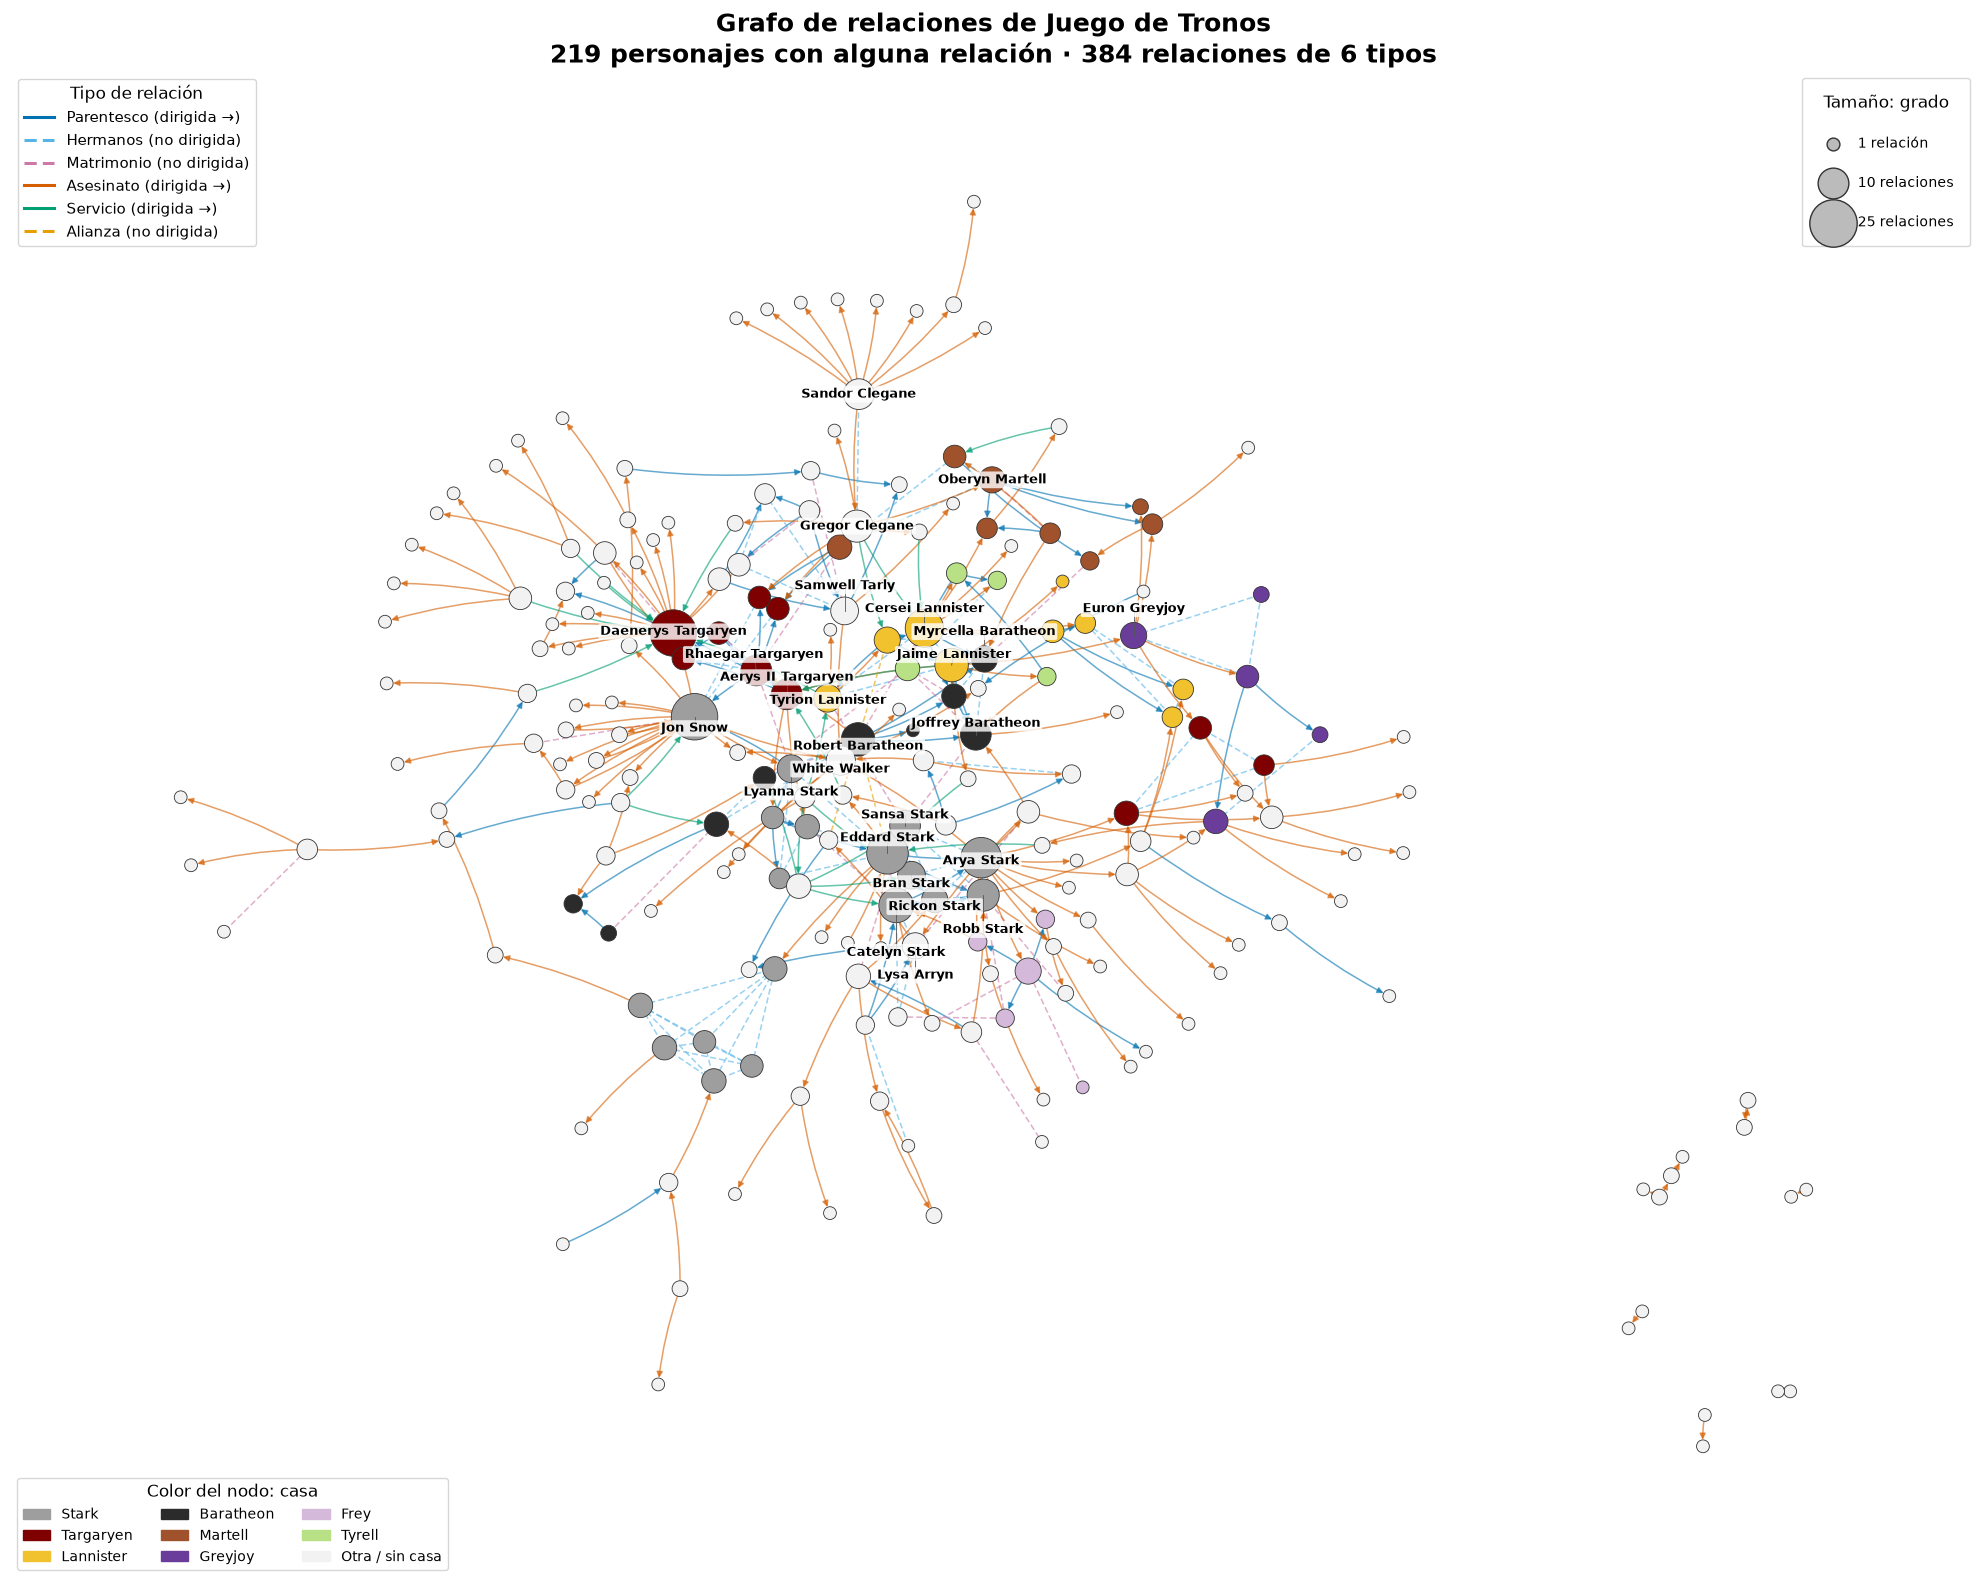

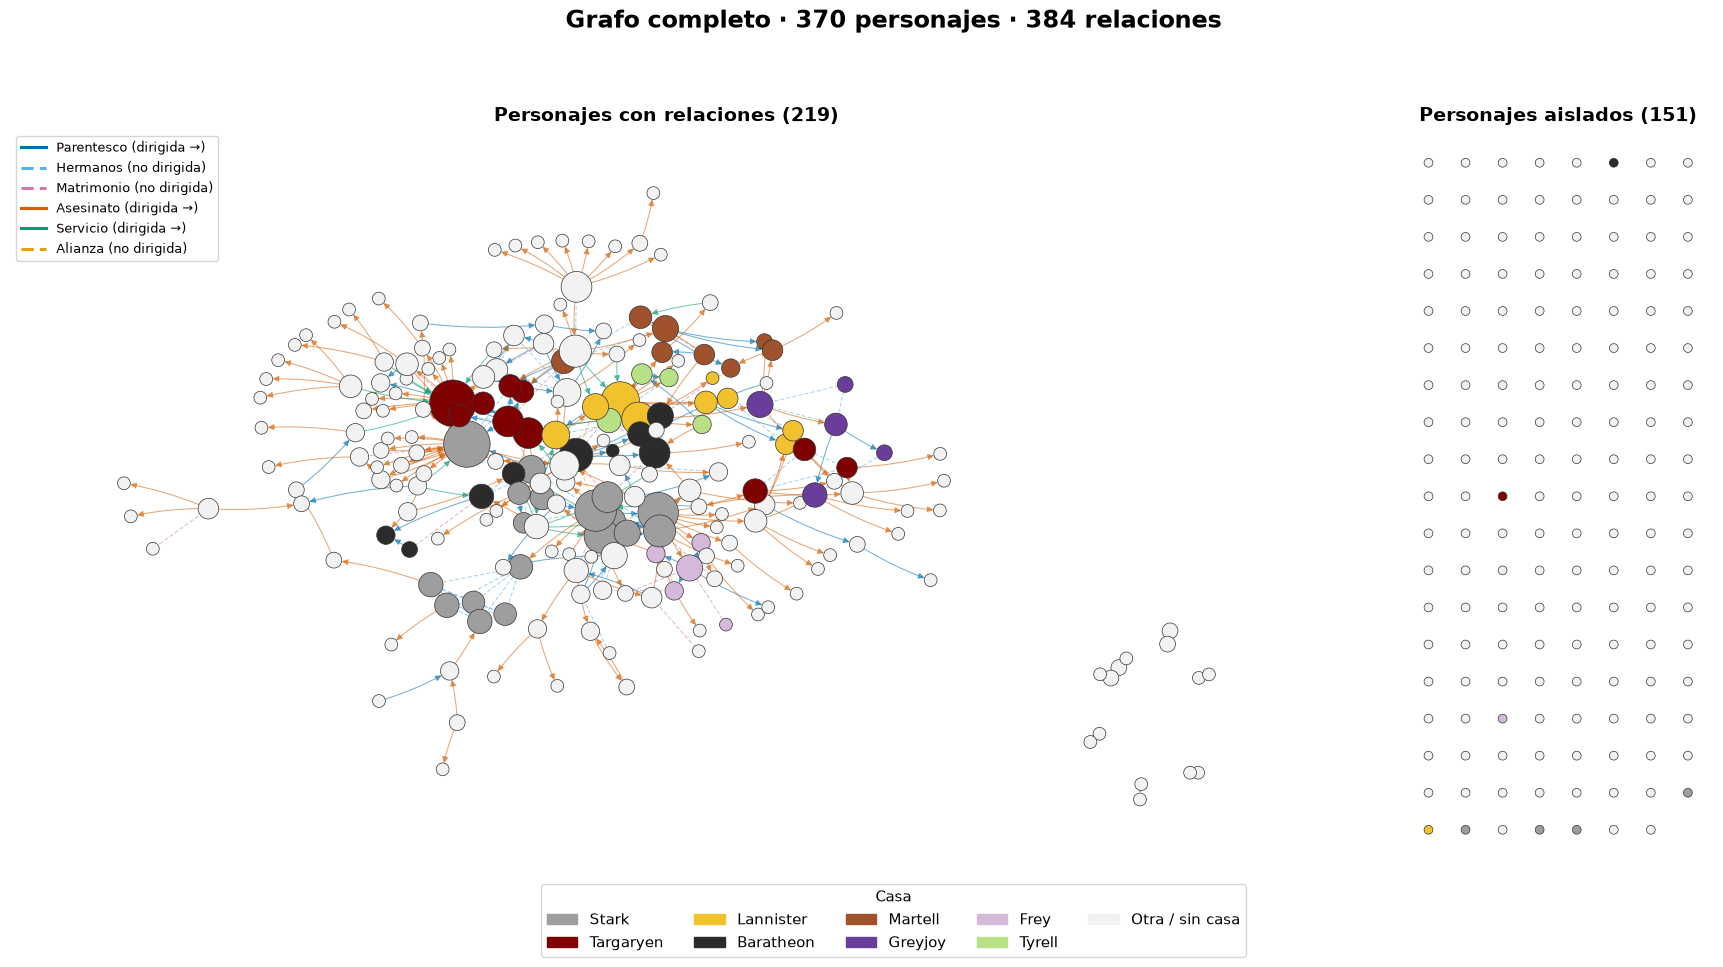

In [5]:
COLORES_REL = {            # paleta Okabe-Ito (apta para daltonismo)
    "parentesco": "#0072B2",
    "hermanos":   "#56B4E9",
    "matrimonio": "#CC79A7",
    "asesinato":  "#D55E00",
    "servicio":   "#009E73",
    "alianza":    "#E69F00",
}
DIRIGIDA = {tipo: dirigida for tipo, dirigida, _ in RELACIONES.values()}

casas_top = [c for c, _ in Counter(nx.get_node_attributes(G_rel, "house").values()).most_common()
             if c != "Sin casa"][:8]
# Colores "heráldicos", elegidos para no confundirse con los colores de las aristas
COLORES_CASA_HERALDICOS = {"Stark": "#9e9e9e", "Targaryen": "#7f0000", "Lannister": "#f2c12e",
                           "Baratheon": "#2b2b2b", "Martell": "#a0522d", "Greyjoy": "#6a3d9a",
                           "Frey": "#d4b9da", "Tyrell": "#b8e186", "Tully": "#1f3a93", "Mormont": "#556b2f"}
COLORES_CASA = {c: COLORES_CASA_HERALDICOS.get(c, "#7a7a7a") for c in casas_top}
COLOR_SIN_CASA = "#f2f2f2"


def color_casa(n):
    return COLORES_CASA.get(G.nodes[n]["house"], COLOR_SIN_CASA)


def dibujar_aristas_por_tipo(H, pos, ax, nodelist, node_size, alpha=0.6, width=1.1):
    """Dibuja las aristas de H agrupadas por tipo: continuas con flecha si son dirigidas, discontinuas si no."""
    for tipo, color in COLORES_REL.items():
        aristas = [(u, v) for u, v, d in H.edges(data=True) if d["relation"] == tipo]
        if not aristas:
            continue
        if DIRIGIDA[tipo]:
            nx.draw_networkx_edges(H, pos, edgelist=aristas, ax=ax, edge_color=color, alpha=alpha, width=width,
                                   arrows=True, arrowstyle="-|>", arrowsize=9, nodelist=nodelist,
                                   node_size=node_size, connectionstyle="arc3,rad=0.06")
        else:
            nx.draw_networkx_edges(H, pos, edgelist=aristas, ax=ax, edge_color=color, alpha=alpha, width=width,
                                   style=(0, (4, 2)), arrows=False)


def etiquetas(ax, pos, nodos, size=9, iteraciones=300):
    """Etiquetas con fondo blanco. Las que se solapan se separan iterativamente
    (repulsión entre cajas) y se unen a su nodo con una línea fina."""
    fig = ax.figure
    fig.canvas.draw()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    ancho_in, alto_in = ax.get_window_extent().width / fig.dpi, ax.get_window_extent().height / fig.dpi
    car = 0.7 * size / 72 * (x1 - x0) / ancho_in            # ancho aproximado de un carácter (unidades de datos)
    alto = 1.5 * size / 72 * (y1 - y0) / alto_in              # alto de una línea de texto
    nodos = list(nodos)
    orig = np.array([pos[n] for n in nodos], dtype=float)
    p = orig.copy()
    semiancho = np.array([car * len(n) / 2 + car for n in nodos])
    for _ in range(iteraciones):
        movido = False
        for i in range(len(nodos)):
            for j in range(i + 1, len(nodos)):
                dx, dy = p[j] - p[i]
                sx = semiancho[i] + semiancho[j] - abs(dx)
                sy = alto - abs(dy)
                if sx > 0 and sy > 0:                          # las cajas se solapan
                    movido = True
                    if sy < sx:                                # separar por el eje con menos solape
                        d = (sy / 2 + 1e-9) * (1 if dy >= 0 else -1)
                        p[i, 1] -= d; p[j, 1] += d
                    else:
                        d = (sx / 2 + 1e-9) * (1 if dx >= 0 else -1)
                        p[i, 0] -= d; p[j, 0] += d
        if not movido:
            break
    for n, (xo, yo), (x, y) in zip(nodos, orig, p):
        if math.hypot(x - xo, y - yo) > alto * 0.3:
            ax.plot([xo, x], [yo, y], color="#555555", lw=0.6, zorder=4)
        ax.text(x, y, n, fontsize=size, ha="center", va="center", fontweight="bold", zorder=5,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))


def leyenda_relaciones(titulo="Tipo de relación"):
    return [Line2D([0], [0], color=c, lw=2.2, linestyle="-" if DIRIGIDA[t] else (0, (4, 2)),
                   label=f"{t.capitalize()} ({'dirigida →' if DIRIGIDA[t] else 'no dirigida'})")
            for t, c in COLORES_REL.items()]


def leyenda_casas():
    return [Patch(color=c, label=casa) for casa, c in COLORES_CASA.items()] + \
           [Patch(color=COLOR_SIN_CASA, label="Otra / sin casa")]


pos = pos_kk                                    # layout elegido, se reutiliza en 1.2
grado = dict(G_rel.degree())
nodos = list(G_rel.nodes())
tam = [40 + 45 * grado[n] for n in nodos]

fig, ax = plt.subplots(figsize=(20, 16))
dibujar_aristas_por_tipo(G_rel, pos, ax, nodos, tam)
nx.draw_networkx_nodes(G_rel, pos, nodelist=nodos, node_size=tam, ax=ax,
                       node_color=[color_casa(n) for n in nodos], edgecolors="#333333", linewidths=0.6)
etiquetas(ax, pos, sorted(grado, key=grado.get, reverse=True)[:25])

leg1 = ax.legend(handles=leyenda_relaciones(), loc="upper left", title="Tipo de relación",
                 fontsize=11, title_fontsize=12, frameon=True)
ax.add_artist(leg1)
leg2 = ax.legend(handles=leyenda_casas(), loc="lower left", title="Color del nodo: casa",
                 fontsize=10, title_fontsize=12, ncol=3)
ax.add_artist(leg2)
ax.legend(handles=[plt.scatter([], [], s=40 + 45 * g, color="#bbbbbb", edgecolors="#333333") for g in (1, 10, 25)],
          labels=["1 relación", "10 relaciones", "25 relaciones"], loc="upper right",
          title="Tamaño: grado", labelspacing=1.8, borderpad=1.2, fontsize=10, title_fontsize=12)
ax.set_title(f"Grafo de relaciones de Juego de Tronos\n{G_rel.number_of_nodes()} personajes con alguna relación · "
             f"{G_rel.number_of_edges()} relaciones de 6 tipos", fontsize=18)
ax.axis("off")
plt.tight_layout()
guardar_figura(fig, "1_1b_grafo_relaciones")
plt.show()
print(f"La vista de detalle omite los {len(aislados)} aislados, que se incluyen en la vista general.")

# Vista general de los 370 personajes, incluidos los nodos de grado cero.
fig, (ax_red, ax_aislados) = plt.subplots(1, 2, figsize=(18, 10), width_ratios=(3, 1))
dibujar_aristas_por_tipo(G_rel, pos, ax_red, nodos, tam, alpha=0.55, width=0.75)
nx.draw_networkx_nodes(G_rel, pos, nodelist=nodos, node_size=tam, ax=ax_red,
                       node_color=[color_casa(n) for n in nodos], edgecolors="#333333",
                       linewidths=0.5)
ax_red.set_title(f"Personajes con relaciones ({len(nodos)})")
ax_red.legend(handles=leyenda_relaciones(), loc="upper left", fontsize=9)
ax_red.axis("off")

orden_aislados = sorted(aislados)
columnas = 8
ax_aislados.scatter([i % columnas for i in range(len(orden_aislados))],
                    [-(i // columnas) for i in range(len(orden_aislados))],
                    s=40, c=[color_casa(n) for n in orden_aislados],
                    edgecolors="#333333", linewidths=0.5)
ax_aislados.set_title(f"Personajes aislados ({len(orden_aislados)})")
ax_aislados.set_xlim(-0.7, columnas - 0.3)
ax_aislados.set_aspect("equal", adjustable="box")
ax_aislados.axis("off")

fig.suptitle(f"Grafo completo · {G.number_of_nodes()} personajes · {G.number_of_edges()} relaciones",
             fontsize=17, fontweight="bold")
fig.legend(handles=leyenda_casas(), loc="lower center", ncol=5, title="Casa",
           bbox_to_anchor=(0.5, 0.025))
fig.tight_layout(rect=(0, 0.11, 1, 0.94))
guardar_figura(fig, "1_1c_grafo_completo")
plt.show()

**¿Qué tipo de grafo has decidido utilizar (dirigido, no dirigido o mixto)? ¿Por qué?**

Un grafo **mixto**, implementado con `nx.MultiDiGraph`. Las relaciones asimétricas (parentesco padre→hijo, asesinato asesino→víctima y servicio sirviente→señor) son dirigidas porque su sentido aporta información; las simétricas (hermanos, matrimonio y alianza) no lo son y se almacenan una sola vez por pareja con el atributo `directed=False`, de modo que no cuentan doble en el grado. Se usa un multigrafo porque entre dos personajes puede haber varias relaciones a la vez (p. ej. hermanos y asesino/víctima).

**¿Qué criterio has seguido para definir el tamaño y color de los nodos?**

El **tamaño** es proporcional al **grado** (número total de relaciones), como pide el enunciado, de forma que los personajes más conectados (Daenerys, Jon, Eddard, Arya, Cersei…) destacan de inmediato. El **color** representa la **casa** del personaje: con él se ve que las relaciones familiares quedan dentro de cada casa y que los asesinatos conectan casas distintas. Los colores de los nodos son tonos "heráldicos" apagados para no confundirse con los colores de las aristas, que codifican el tipo de relación (paleta Okabe-Ito, apta para daltónicos, reforzada con línea continua/discontinua para dirigida/no dirigida).

**¿Qué layout te ha resultado más adecuado para representar las relaciones?**

`kamada_kawai_layout` para la componente gigante: a diferencia de `spring_layout`, mantiene las distancias del grafo, separa las familias en racimos y deja en el centro a los personajes que actúan de puente. Las 6 componentes pequeñas (2–4 personajes) se colocan aparte en un lateral para que no ensucien el núcleo. Los 151 personajes sin relaciones seleccionadas aparecen en un panel propio en la vista general. Así se muestra el conjunto completo y se puede examinar la red de relaciones en la vista de detalle.

## Apartado 1.2: Análisis de centralidad y relevancia de personajes

### 1. Cálculo de las medidas de centralidad
Vamos a utilizar cinco métricas:

| Métrica | Qué mide | Grafo sobre el que se calcula |
| :--- | :--- | :--- |
| **Grado (degree)** | Número de conexiones directas de un personaje (normalizado). | No dirigido simple |
| **Intermediación (betweenness)** | Cuántas veces aparece un personaje en los caminos más cortos entre otros: personajes "puente". | No dirigido simple |
| **Cercanía (closeness)** | Inverso de la distancia media a los nodos alcanzables, con ajuste por el tamaño relativo de la componente. | No dirigido simple |
| **Vector propio (eigenvector)** | Un personaje es importante si está conectado con personajes importantes. | No dirigido simple |
| **PageRank** | Importancia que "fluye" siguiendo la dirección de las aristas. | Dirigido (las no dirigidas en ambos sentidos) |

Las cuatro primeras se calculan sobre la proyección simple y no dirigida de los **370 personajes**, incluidos los 151 aislados. Esta proyección cuenta vecinos únicos y reúne los vínculos entre un mismo par. PageRank usa los mismos 370 nodos con las direcciones originales y representa en ambos sentidos los vínculos simétricos. Los aislados tienen grado, cercanía e intermediación cero, y reciben la contribución de base de PageRank.

In [6]:
# Versión dirigida simple: las relaciones no dirigidas se añaden en ambos sentidos
G_dir = nx.DiGraph()
G_dir.add_nodes_from(G)
for u, v, d in G_rel.edges(data=True):
    G_dir.add_edge(u, v)
    if not d["directed"]:
        G_dir.add_edge(v, u)

G_cent = nx.Graph(G)
centralidades = {
    "Grado": nx.degree_centrality(G_cent),
    "Intermediación": nx.betweenness_centrality(G_cent),
    "Cercanía": nx.closeness_centrality(G_cent),
    "Vector propio": nx.eigenvector_centrality(G_cent, max_iter=2000),
    "PageRank": nx.pagerank(G_dir, alpha=0.85),
}
df_cent = pd.DataFrame(centralidades)
df_cent.sort_values("Grado", ascending=False).head(10).round(3)

,Grado,Intermediación,Cercanía,Vector propio,PageRank
Daenerys Targaryen,0.062,0.081,0.168,0.100,0.011
Jon Snow,0.051,0.067,0.173,0.089,0.016
Eddard Stark,0.051,0.067,0.181,0.364,0.011
Arya Stark,0.049,0.077,0.173,0.311,0.010
Cersei Lannister,0.043,0.033,0.162,0.158,0.004
Catelyn Stark,0.035,0.016,0.161,0.302,0.009
Robert Baratheon,0.033,0.038,0.178,0.181,0.008
Jaime Lannister,0.030,0.022,0.158,0.124,0.003
Robb Stark,0.030,0.022,0.158,0.258,0.016
Sansa Stark,0.027,0.036,0.177,0.288,0.013


### 2. Visualización de los 10 personajes principales por métrica
Una gráfica de barras horizontales por métrica: las barras horizontales permiten leer los nombres sin rotarlos, se ordenan de mayor a menor (el primero arriba) y se anota el valor exacto al final de cada barra. Cada métrica tiene su propio eje X porque las escalas no son comparables entre sí. El color de la barra es el de la casa del personaje (mismo código de color que en el grafo), lo que permite ver qué casas dominan cada ranking.

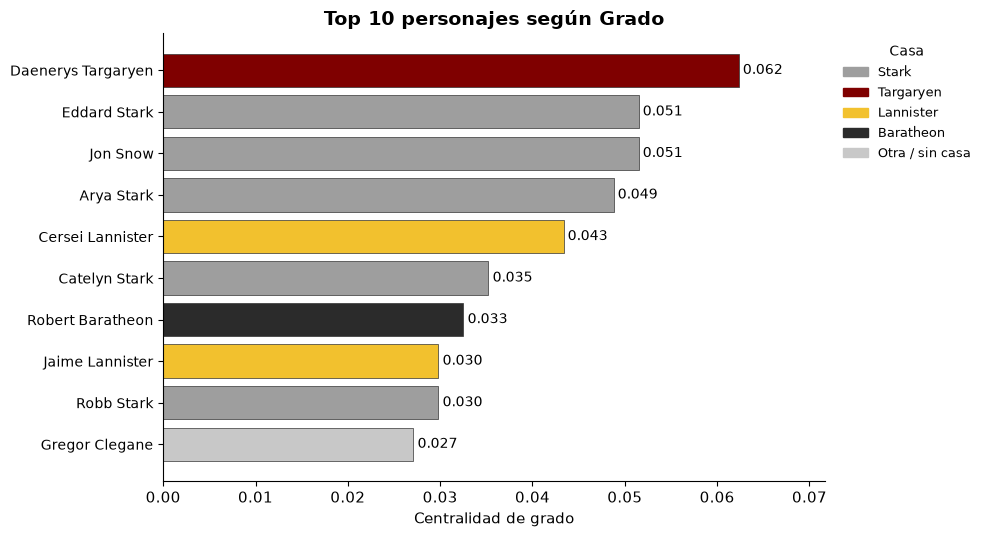

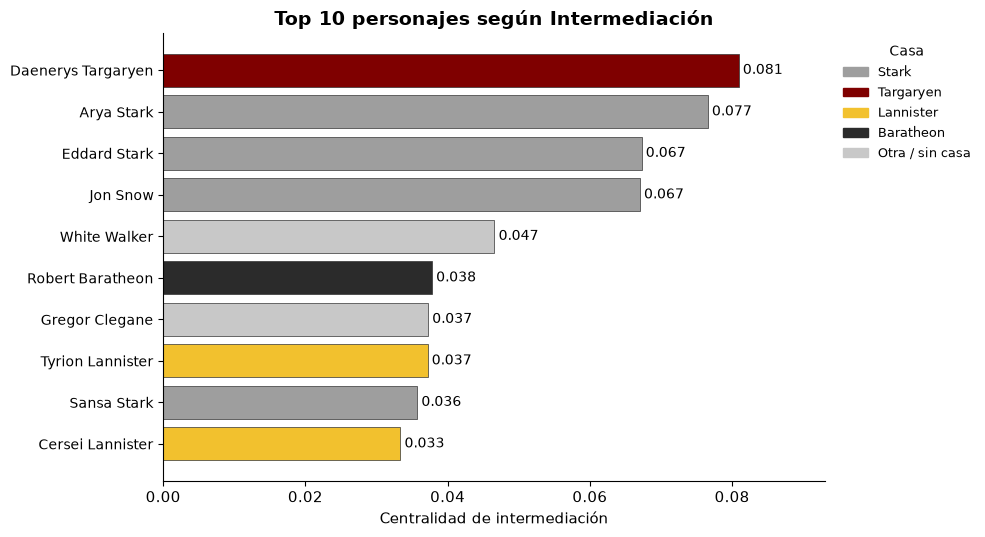

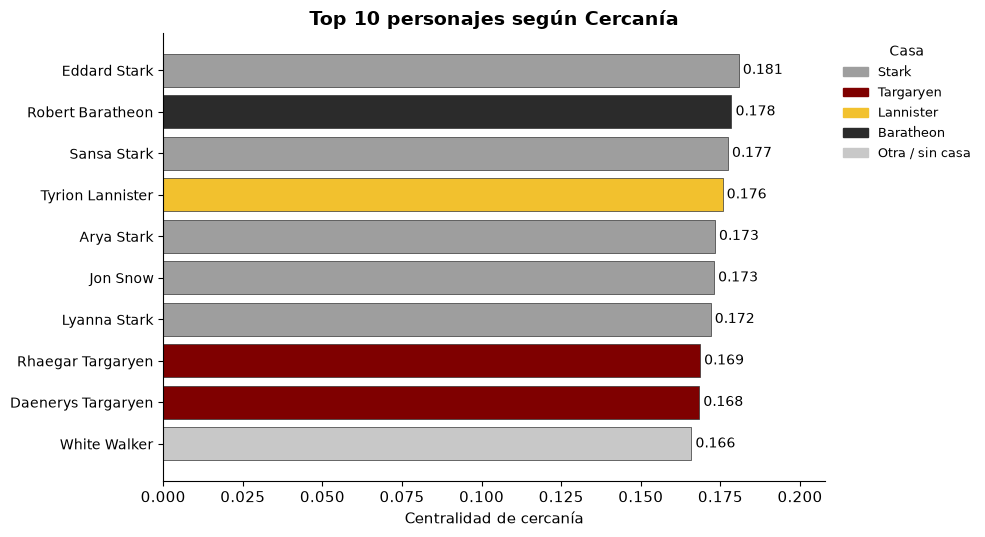

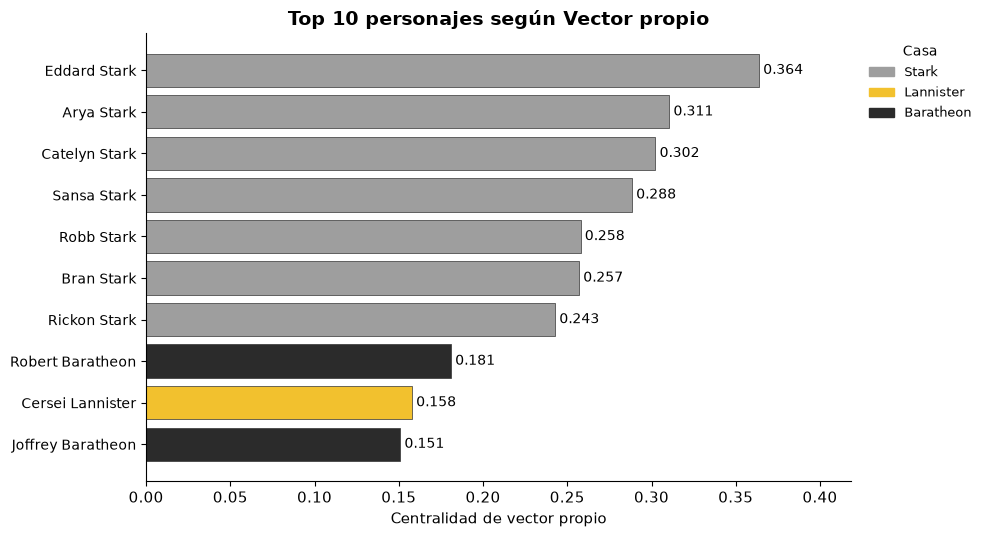

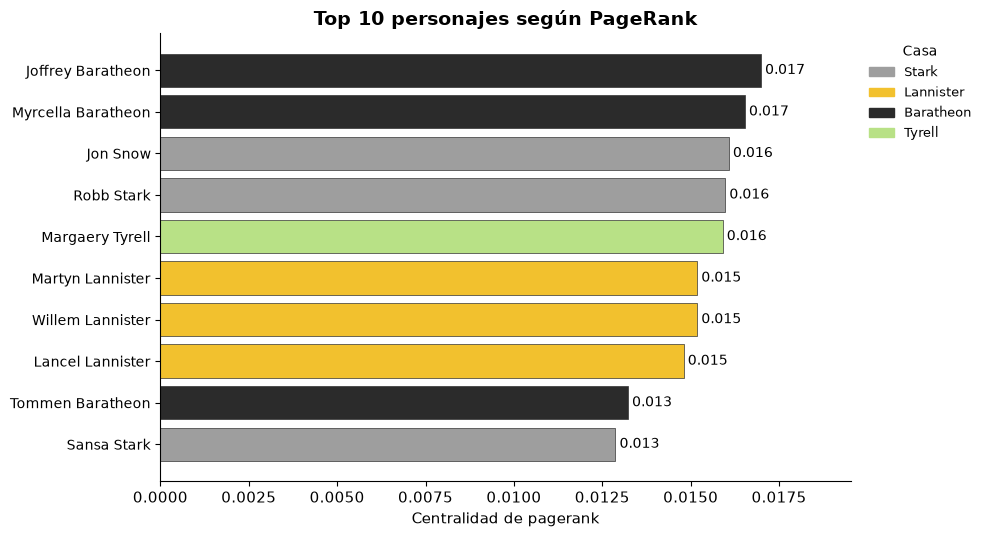

In [7]:
COLOR_BARRA_OTRA = "#c8c8c8"


def grafico_top10(ax, metrica, valores, n=10):
    top = valores.sort_values(ascending=False, kind="stable").head(n)[::-1]
    casas = [G.nodes[p]["house"] for p in top.index]
    colores = [COLORES_CASA.get(c, COLOR_BARRA_OTRA) for c in casas]
    barras = ax.barh(top.index, top.values, color=colores, edgecolor="#333333", linewidth=0.5)
    ax.bar_label(barras, labels=[f"{v:.3f}" for v in top.values], padding=3, fontsize=10)
    ax.set_xlim(0, top.max() * 1.15)
    ax.set_title(f"Top {n} personajes según {metrica}")
    ax.set_xlabel(f"Centralidad de {metrica.lower()}")
    ax.tick_params(axis="y", labelsize=10)
    # Leyenda solo con las casas presentes en este ranking, fuera del área de las barras
    presentes = [c for c in COLORES_CASA if c in casas]
    handles = [Patch(color=COLORES_CASA[c], label=c) for c in presentes]
    if any(c not in COLORES_CASA for c in casas):
        handles.append(Patch(color=COLOR_BARRA_OTRA, label="Otra / sin casa"))
    ax.legend(handles=handles, title="Casa", fontsize=9, title_fontsize=10,
              loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)


for metrica in centralidades:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    grafico_top10(ax, metrica, df_cent[metrica])
    plt.tight_layout()
    guardar_figura(fig, f"1_2_top10_{metrica.lower().replace(' ', '_')}")
    plt.show()

Para comparar las métricas entre sí resumimos los cinco rankings en un mapa de calor: cada fila es un personaje que aparece en algún top 10 y cada celda indica su **posición** en ese ranking (vacía si no está en el top 10). Los colores más oscuros indican mejor posición.

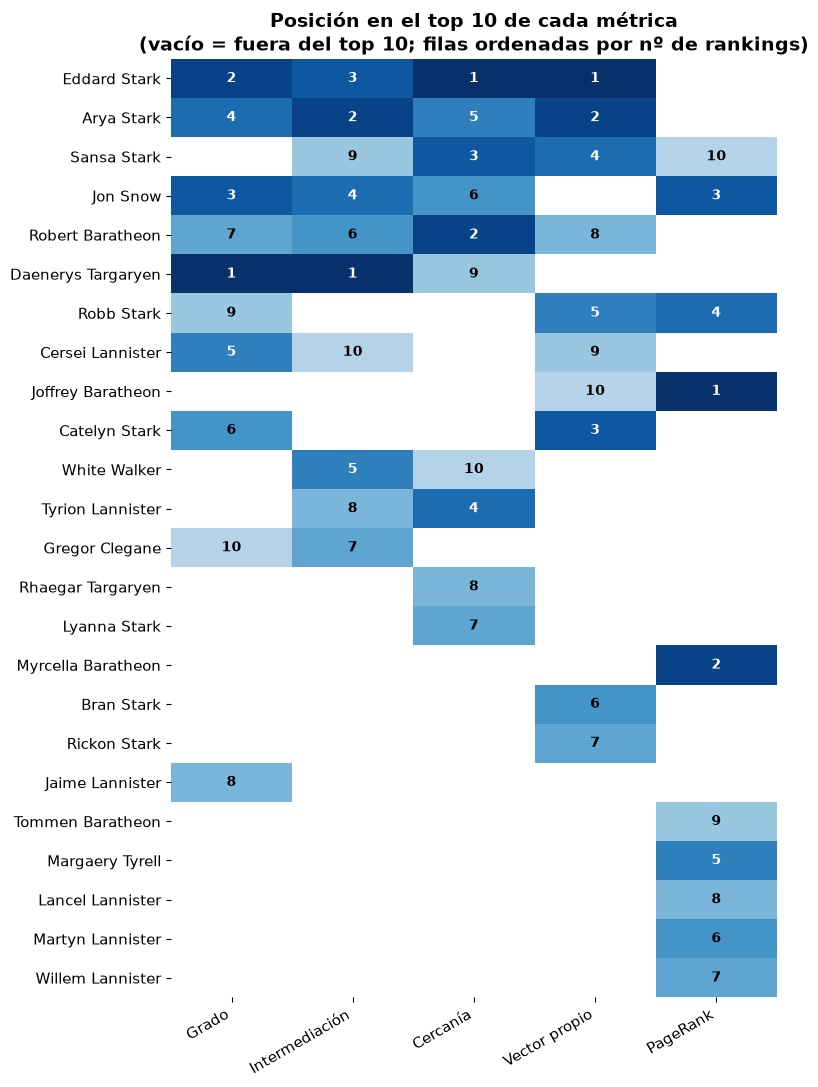

In [8]:
rangos = df_cent.rank(ascending=False, method="first")
en_top = rangos[(rangos <= 10).any(axis=1)]
# Orden: primero los que están en más rankings; a igualdad, mejor posición media
orden_filas = pd.DataFrame({"n": (en_top <= 10).sum(axis=1), "media": en_top.mean(axis=1)}) \
    .sort_values(["n", "media"], ascending=[False, True]).index
matriz = en_top.loc[orden_filas].where(en_top <= 10)

fig, ax = plt.subplots(figsize=(8, 11))
im = ax.imshow(matriz.values, cmap="Blues_r", vmin=1, vmax=14, aspect="auto")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        v = matriz.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, int(v), ha="center", va="center", fontsize=10,
                    color="white" if v <= 5 else "black", fontweight="bold")
ax.set_xticks(range(matriz.shape[1]), matriz.columns, rotation=30, ha="right")
ax.set_yticks(range(matriz.shape[0]), matriz.index)
ax.set_title("Posición en el top 10 de cada métrica\n(vacío = fuera del top 10; filas ordenadas por nº de rankings)")
ax.spines[:].set_visible(False)
plt.tight_layout()
guardar_figura(fig, "1_2_comparacion_rankings")
plt.show()

### 3. Visualización final según la centralidad de intermediación

Elegimos la **intermediación** porque destaca a quienes conectan grupos. Daenerys, Arya, Eddard y Jon encabezan el ranking, y también aparecen personajes puente como Gregor Clegane y Tyrion. Reutilizamos el layout del apartado 1.1 para facilitar la comparación. El área de cada nodo aumenta linealmente con la intermediación, a partir de un tamaño mínimo que permite ver los nodos de valor cero. Las aristas van en gris y se etiquetan los 20 personajes de mayor intermediación. La figura se centra en los 219 personajes con relaciones, aunque las métricas se calculan para los 370.

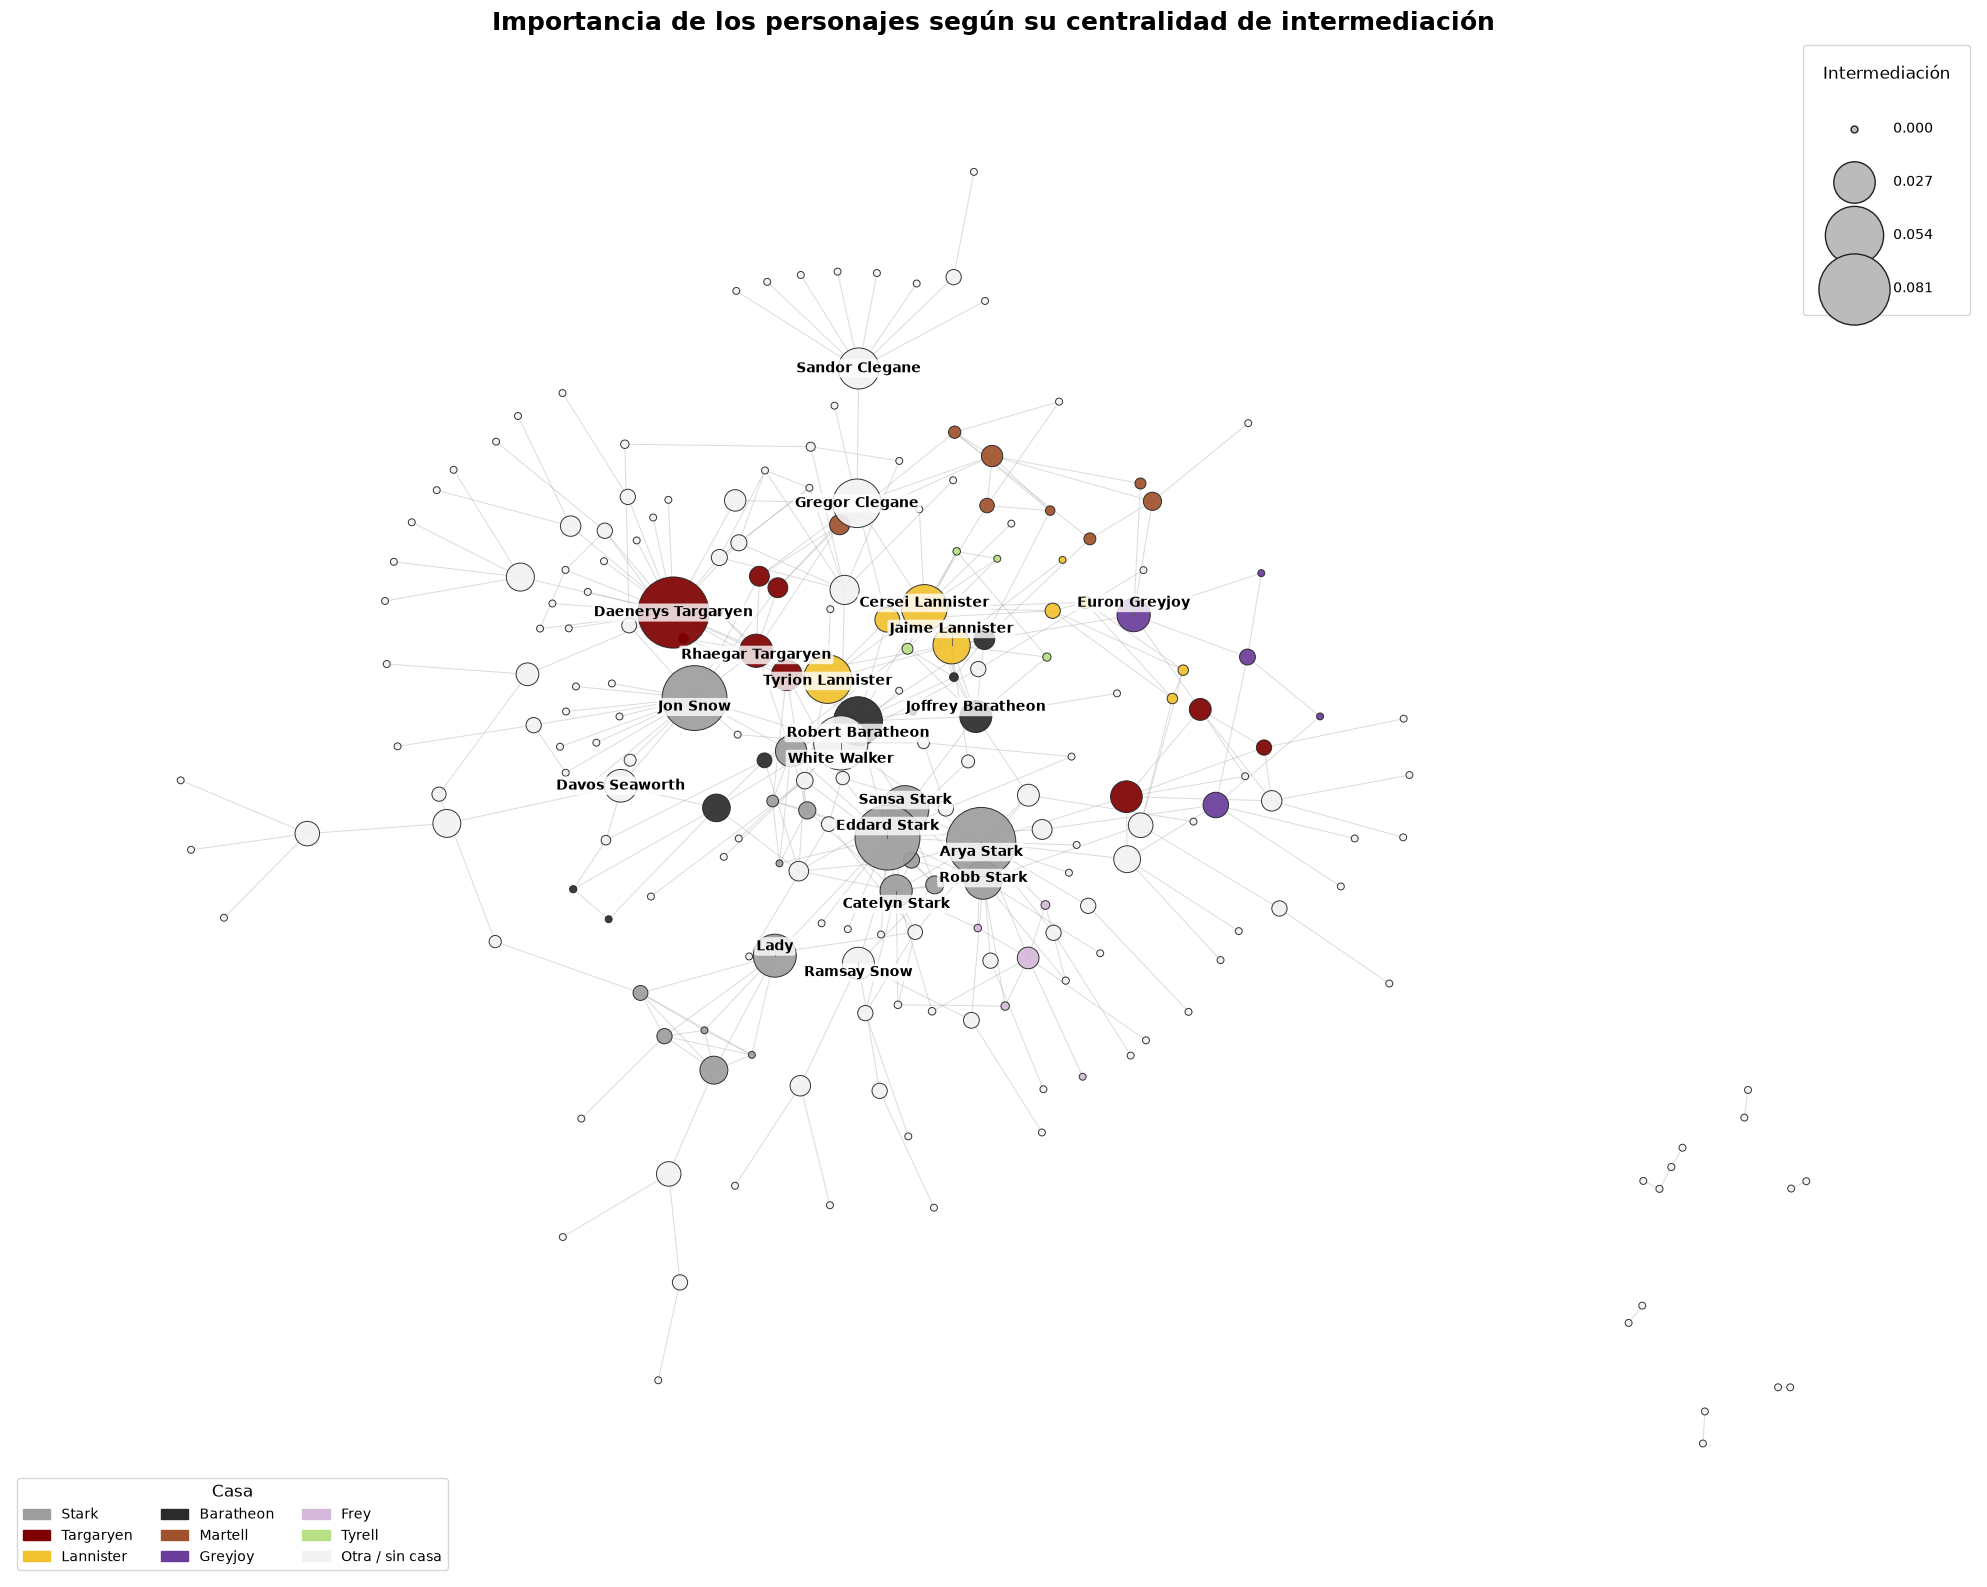

In [9]:
btw = centralidades["Intermediación"]
bmax = max(btw.values())


def tam_btw(v):
    return 25 + 2600 * v / bmax


tam = [tam_btw(btw[n]) for n in nodos]
orden = sorted(nodos, key=lambda n: btw[n])           # los grandes se dibujan encima

fig, ax = plt.subplots(figsize=(20, 16))
nx.draw_networkx_edges(G_und, pos, ax=ax, edge_color="#b0b0b0", alpha=0.45, width=0.7)
nx.draw_networkx_nodes(G_rel, pos, nodelist=orden, node_size=[tam_btw(btw[n]) for n in orden], ax=ax,
                       node_color=[color_casa(n) for n in orden], edgecolors="#222222", linewidths=0.7, alpha=0.92)
etiquetas(ax, pos, sorted(btw, key=btw.get, reverse=True)[:20], size=10)

leg = ax.legend(handles=leyenda_casas(), loc="lower left", title="Casa", ncol=3, fontsize=10, title_fontsize=12)
ax.add_artist(leg)
muestras = [0, bmax / 3, 2 * bmax / 3, bmax]
ax.legend(handles=[plt.scatter([], [], s=tam_btw(v), color="#bbbbbb", edgecolors="#222222") for v in muestras],
          labels=[f"{v:.3f}" for v in muestras], loc="upper right", title="Intermediación",
          labelspacing=2.8, handletextpad=1.8, borderpad=1.4, fontsize=10, title_fontsize=12)
ax.set_title("Importancia de los personajes según su centralidad de intermediación", fontsize=18)
ax.axis("off")
plt.tight_layout()
guardar_figura(fig, "1_2_grafo_intermediacion")
plt.show()

**1. ¿Qué diferencias observas entre las distintas medidas de centralidad?**

- **Grado** premia a quien tiene muchas relaciones directas: Daenerys (dragones, asesinatos, matrimonios), Jon, Eddard, Arya y Cersei. Favorece a los miembros de familias grandes y a los "asesinos en serie" (Arya).
- **Intermediación** destaca a los personajes **puente**: además de los protagonistas aparecen el *White Walker*, Gregor Clegane y Tyrion. Sus posiciones señalan vínculos entre grupos dentro de la red.
- **Cercanía** favorece a personajes próximos a muchos miembros de la red. Lyanna Stark y Rhaegar Targaryen entran en el *top 10* gracias a los caminos cortos que los conectan con distintas familias.
- **Vector propio** está dominado por **un solo racimo**: los Stark (Eddard, Arya, Catelyn, Sansa, Robb, Bran, Rickon). Al premiar estar conectado con nodos importantes, se concentra en la familia más densa.
- **PageRank (dirigido)** es la más distinta: como la importancia fluye siguiendo las flechas (padre→hijo, asesino→víctima), acumulan valor los **hijos y las víctimas**: Joffrey, Myrcella, Tommen, Robb o los Lannister menores (Willem, Martyn, Lancel).

**2. ¿Los personajes más "centrales" coinciden con los más importantes en la historia?**

Hay coincidencias con el protagonismo de la serie. Jon, Arya y Eddard figuran en cuatro de los cinco *top 10*. Tyrion entra en dos, intermediación y cercanía, y queda fuera del de grado. PageRank también coloca en posiciones altas a secundarios como Willem y Martyn Lannister. Estas métricas describen posiciones en la red de relaciones elegida, mientras que el protagonismo narrativo también depende de la presencia en pantalla y del papel en la trama.

**3. ¿Cómo influye la forma de calcular la centralidad en la interpretación del grafo?**

Mucho: cada métrica responde a una pregunta distinta (¿cuántos vínculos tiene?, ¿conecta grupos?, ¿está cerca de todos?, ¿está rodeado de importantes?, ¿recibe relaciones?). Además, las decisiones de modelado también influyen: considerar el grafo dirigido o no puede cambiar el ranking de PageRank, y elegir qué tipos de relación incluir cambia todos. Por eso, para representar la importancia narrativa hemos elegido la **intermediación**, que es la que mejor recoge a los protagonistas que hacen avanzar varias tramas.

## Apartado 1.3: Subredes y comunidades

### 1. Creación de subgrafos
Creamos tres subgrafos según el tipo de relación (no dirigidos, sin personajes aislados):
- **Familia:** parentesco, hermanos y matrimonio.
- **Conflicto:** asesinatos.
- **Lealtad:** servicio y alianzas.

In [10]:
GRUPOS_REL = {
    "Familia": {"parentesco", "hermanos", "matrimonio"},
    "Conflicto": {"asesinato"},
    "Lealtad": {"servicio", "alianza"},
}


def subgrafo_por_tipos(tipos):
    """Subgrafo no dirigido simple con las aristas de los tipos indicados (sin nodos aislados)."""
    H = nx.Graph()
    for u, v, d in G_rel.edges(data=True):
        if d["relation"] in tipos:
            H.add_edge(u, v)
    return H


subgrafos = {nombre: subgrafo_por_tipos(tipos) for nombre, tipos in GRUPOS_REL.items()}
pd.DataFrame({
    nombre: {"personajes": H.number_of_nodes(), "relaciones": H.number_of_edges(),
             "componentes conexas": nx.number_connected_components(H),
             "mayor componente": len(max(nx.connected_components(H), key=len))}
    for nombre, H in subgrafos.items()
}).T

,personajes,relaciones,componentes conexas,mayor componente
Familia,109,180,13,69
Conflicto,189,170,23,93
Lealtad,31,27,5,13


### 2. Detección de comunidades
Comparamos dos algoritmos de NetworkX basados en **modularidad** (cuánto más densas son las conexiones dentro de los grupos que entre ellos): `greedy_modularity_communities` y `louvain_communities`. Los aplicamos a la subred familiar (la principal del análisis) y al grafo completo. Fijamos `seed=42` en Louvain para que el resultado sea reproducible.

In [11]:
H_fam = subgrafos["Familia"]
redes = {"Familia": H_fam, "Grafo completo": G_und}

comparacion = {}
for nombre, H in redes.items():
    greedy = nx.community.greedy_modularity_communities(H)
    louvain = nx.community.louvain_communities(H, seed=42)
    comparacion[nombre] = {
        "nº comunidades (greedy)": len(greedy), "modularidad (greedy)": nx.community.modularity(H, greedy),
        "nº comunidades (Louvain)": len(louvain), "modularidad (Louvain)": nx.community.modularity(H, louvain),
    }
pd.DataFrame(comparacion).T.round(3)

,nº comunidades (greedy),modularidad (greedy),nº comunidades (Louvain),modularidad (Louvain)
Familia,19.0,0.784,19.0,0.794
Grafo completo,18.0,0.714,18.0,0.709


Louvain obtiene la mayor modularidad en la subred familiar (0,794 frente a 0,784) y prácticamente la misma que *greedy* en el grafo completo (diferencia de 0,005). Elegimos **Louvain** en ambos casos: da la mejor puntuación en la subred familiar y permite usar el mismo criterio en ambas redes.

In [12]:
def detectar_comunidades(H):
    comunidades = sorted(nx.community.louvain_communities(H, seed=42), key=len, reverse=True)
    filas = []
    for i, com in enumerate(comunidades, start=1):
        miembros = sorted(com)                                  # orden fijo: resultados reproducibles
        casas = Counter(G.nodes[n]["house"] for n in miembros if G.nodes[n]["house"] != "Sin casa")
        sub = H.subgraph(com)
        filas.append({
            "comunidad": i,
            "tamaño": len(com),
            "casa dominante": ", ".join(f"{c} ({k})" for c, k in casas.most_common(2)) or "—",
            "personajes más conectados": ", ".join(sorted(miembros, key=lambda n: -sub.degree(n))[:5]),
        })
    return comunidades, pd.DataFrame(filas).set_index("comunidad")


com_fam, tabla_fam = detectar_comunidades(H_fam)
com_all, tabla_all = detectar_comunidades(G_und)

print(f"Subred familiar: {len(com_fam)} comunidades, {sum(len(c) >= 4 for c in com_fam)} con 4 o más personajes")
display(tabla_fam.head(12))
print(f"Grafo completo: {len(com_all)} comunidades, {sum(len(c) >= 4 for c in com_all)} con 4 o más personajes")
display(tabla_all.head(12))

Subred familiar: 19 comunidades, 9 con 4 o más personajes
Grafo completo: 18 comunidades, 13 con 4 o más personajes


,tamaño,casa dominante,personajes más conectados
comunidad,,,
1,17,"Baratheon (9), Lannister (4)","Cersei Lannister, Robert Baratheon, Jaime Lann..."
2,14,"Frey (5), Tully (3)","Walder Frey, Lysa Arryn, Edmure Tully, Hoster ..."
3,12,"Targaryen (7), Martell (1)","Rhaegar Targaryen, Daenerys Targaryen, Aegon T..."
4,12,Stark (11),"Eddard Stark, Catelyn Stark, Robb Stark, Arya ..."
5,8,Tarly (1),"Samwell Tarly, Dickon Tarly, Melessa Tarly, Ra..."
6,7,Martell (7),"Oberyn Martell, Doran Martell, Ellaria Sand, T..."
7,6,Stark (6),"Ghost, Grey Wind, Lady, Nymeria, Shaggydog"
8,5,Greyjoy (5),"Balon Greyjoy, Aeron Greyjoy, Euron Greyjoy, T..."
9,4,Lannister (4),"Kevan Lannister, Lancel Lannister, Martyn Lann..."


,tamaño,casa dominante,personajes más conectados
comunidad,,,
1,43,"Stark (11), Frey (5)","Arya Stark, Eddard Stark, Catelyn Stark, Robb ..."
2,27,"Martell (7), Targaryen (3)","Jon Snow, Gregor Clegane, Elia Martell, Oberyn..."
3,25,Targaryen (4),"Daenerys Targaryen, Daario Naharis, Khal Drogo..."
4,20,"Greyjoy (5), Targaryen (3)","Theon Greyjoy, Pyat Pree, Rhaegal, Viserion, B..."
5,19,"Baratheon (6), Lannister (5)","Cersei Lannister, Jaime Lannister, Joffrey Bar..."
6,15,"Stark (6), Mormont (2)","Ghost, Shaggydog, Summer, Grey Wind, Lady"
7,11,—,"White Walker, Howland Reed, Meera Reed, Jojen ..."
8,11,Baratheon (3),"Bronn, Shireen Baratheon, Stannis Baratheon, D..."
9,10,Tarly (1),"Samwell Tarly, Dickon Tarly, Melessa Tarly, Ra..."


### 3. Visualización de las comunidades
Decisiones de diseño:
- **Color = comunidad.** Cada grupo recibe un color distinto. La paleta alterna familias cromáticas y los identificadores C1, C2, etc. permiten reconocer también los grupos de tonos próximos.
- **Tamaño = grado dentro de su comunidad** (número de relaciones con miembros de su misma comunidad), tal y como pide el enunciado.
- **Layout en dos niveles** (función `layout_comunidades`): un layout de fuerzas sobre todo el grafo mezcla las comunidades (lo comprobamos: quedaban todas apelotonadas en el centro). En su lugar, cada comunidad principal ocupa su propia zona en una circunferencia, con un radio proporcional a √tamaño, y dentro de ella se aplica Kamada-Kawai. El orden alrededor de la circunferencia se elige para que las comunidades más conectadas entre sí queden contiguas, lo que acorta las aristas entre comunidades (gris discontinuo). Las comunidades pequeñas se colocan en una fila inferior.
- **Etiquetas:** los tres personajes con mayor grado interno de cada comunidad principal, el identificador de cada grupo y una leyenda con su tamaño y sus casas más representadas.

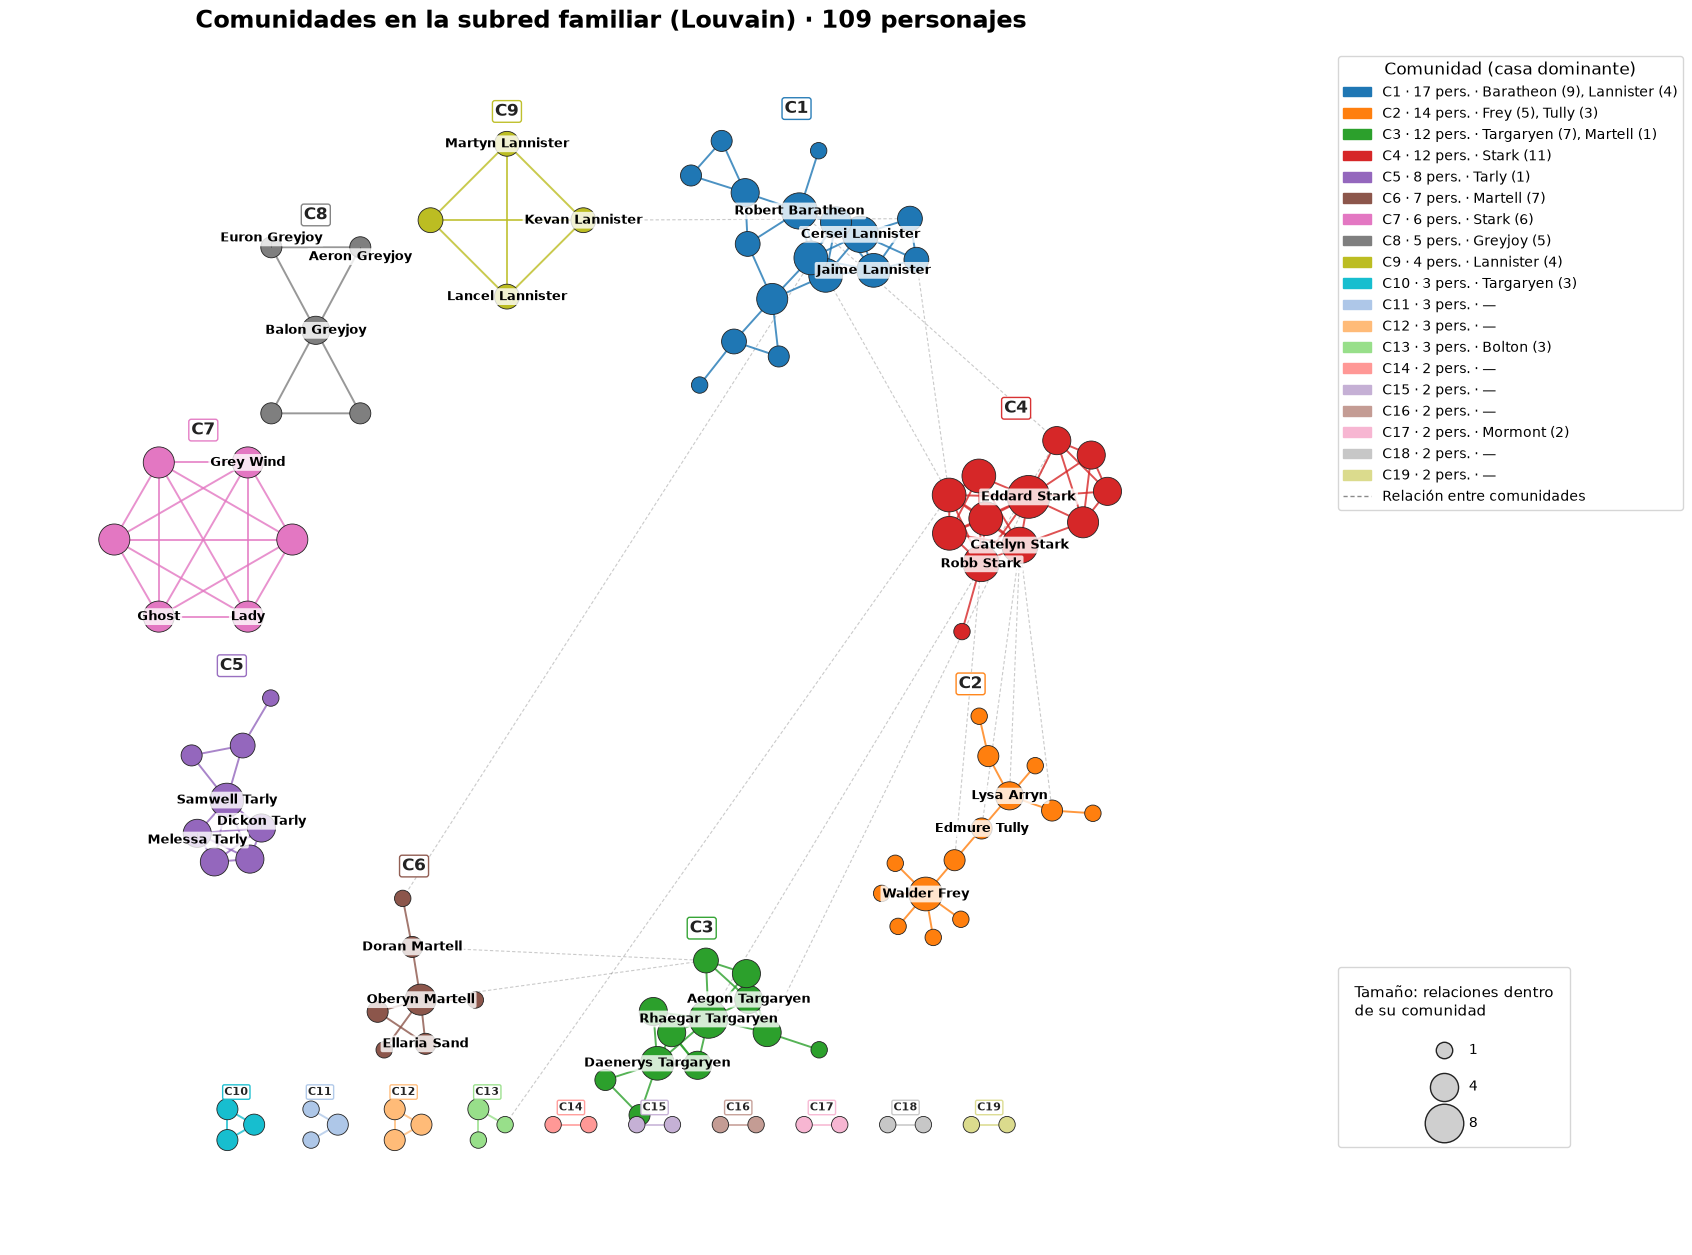

In [13]:
# Primero se usan los tonos oscuros y después sus variantes claras.
_tab20 = mpl.colormaps["tab20"].colors
PALETA_COMUNIDADES = list(_tab20[::2]) + list(_tab20[1::2])


def paleta(i):
    return PALETA_COMUNIDADES[i]


def layout_comunidades(H, comunidades, min_tam=4, seed=42):
    """Layout en dos niveles: las comunidades principales se colocan en una circunferencia
    (ordenadas para que las más conectadas entre sí queden contiguas) y cada una se dibuja
    internamente con Kamada-Kawai en un círculo de radio proporcional a sqrt(tamaño).
    Las comunidades pequeñas se colocan en una fila debajo."""
    principales = [c for c in comunidades if len(c) >= min_tam]
    pequenas = [c for c in comunidades if len(c) < min_tam]
    idx = {n: i for i, c in enumerate(principales) for n in c}
    enlaces = Counter()
    for u, v in H.edges():
        if u in idx and v in idx and idx[u] != idx[v]:
            enlaces[frozenset((idx[u], idx[v]))] += 1

    # Orden en la circunferencia: voraz, siempre la comunidad más conectada con la última colocada
    orden, restantes = [0], set(range(1, len(principales)))
    while restantes:
        ult = orden[-1]
        sig = max(restantes, key=lambda j: (enlaces[frozenset((ult, j))], len(principales[j])))
        orden.append(sig)
        restantes.remove(sig)

    radios = [0.55 * math.sqrt(len(c)) + 0.4 for c in principales]
    R = max(1.4 * sum(2 * r for r in radios) / (2 * math.pi), 2.5)
    pos, angulo = {}, math.pi / 2
    total = sum(2 * radios[i] for i in orden)
    for i in orden:
        angulo -= math.pi * (2 * radios[i]) / total            # avanzar medio "hueco" de la comunidad
        centro = np.array([R * math.cos(angulo), R * math.sin(angulo)])
        angulo -= math.pi * (2 * radios[i]) / total
        sub = H.subgraph(principales[i])
        interno = nx.kamada_kawai_layout(sub) if nx.is_connected(sub) else nx.spring_layout(sub, seed=seed)
        for n, p in interno.items():
            pos[n] = centro + radios[i] * np.asarray(p)

    # Comunidades pequeñas en una fila inferior
    for k, com in enumerate(pequenas):
        x = -R + 2 * R * (k + 0.5) / max(len(pequenas), 1)
        interno = nx.circular_layout(H.subgraph(com))
        for n, p in interno.items():
            pos[n] = np.array([x, -R - 1.6]) + 0.35 * np.asarray(p)
    return pos


def dibujar_comunidades(H, comunidades, tabla, titulo, nombre_pdf, min_tam=4, n_etiquetas=3, figsize=(20, 15)):
    principales = [c for c in comunidades if len(c) >= min_tam]
    color_com, id_com = {}, {}
    for i, com in enumerate(comunidades):
        for n in com:
            id_com[n] = i
            color_com[n] = paleta(i)

    # Grado de cada nodo dentro de su propia comunidad
    grado_intra = {}
    for com in comunidades:
        sub = H.subgraph(com)
        grado_intra.update(dict(sub.degree()))

    pos_c = layout_comunidades(H, comunidades, min_tam)

    internas = [(u, v) for u, v in H.edges() if id_com[u] == id_com[v]]
    externas = [(u, v) for u, v in H.edges() if id_com[u] != id_com[v]]
    nodos_h = list(H.nodes())

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_aspect("equal")
    ax.axis("off")
    fig.subplots_adjust(left=0.01, right=0.79, top=0.94, bottom=0.01)
    nx.draw_networkx_edges(H, pos_c, edgelist=externas, ax=ax, edge_color="#8a8a8a", alpha=0.45,
                           width=0.8, style=(0, (3, 2)))
    nx.draw_networkx_edges(H, pos_c, edgelist=internas, ax=ax, alpha=0.8, width=1.4,
                           edge_color=[color_com[u] for u, _ in internas])
    nx.draw_networkx_nodes(H, pos_c, nodelist=nodos_h, ax=ax,
                           node_size=[50 + 90 * grado_intra[n] for n in nodos_h],
                           node_color=[color_com[n] for n in nodos_h], edgecolors="#222222", linewidths=0.6)
    a_etiquetar = [n for com in principales for n in sorted(sorted(com), key=lambda n: -grado_intra[n])[:n_etiquetas]]
    etiquetas(ax, pos_c, a_etiquetar, size=9)

    for i, com in enumerate(comunidades):
        xs, ys = zip(*(pos_c[n] for n in com))
        grande = len(com) >= min_tam
        ax.text(np.mean(xs), max(ys) + (0.55 if grande else 0.28), f"C{i + 1}",
                fontsize=12 if grande else 8, fontweight="bold", ha="center", color="#222222",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=paleta(i), alpha=0.95))

    handles = [Patch(color=paleta(i), label=f"C{i + 1} · {len(c)} pers. · {tabla.loc[i + 1, 'casa dominante']}")
               for i, c in enumerate(comunidades)]
    handles.append(Line2D([0], [0], color="#8a8a8a", lw=1, linestyle=(0, (3, 2)), label="Relación entre comunidades"))
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.80, 0.93), title="Comunidad (casa dominante)",
               fontsize=10, title_fontsize=12)
    fig.legend(handles=[plt.scatter([], [], s=50 + 90 * g, color="#cfcfcf", edgecolors="#222222") for g in (1, 4, 8)],
               labels=["1", "4", "8"], loc="lower left", bbox_to_anchor=(0.80, 0.08),
               title="Tamaño: relaciones dentro\nde su comunidad", labelspacing=1.6, borderpad=1.2,
               fontsize=10, title_fontsize=11)
    ax.set_title(titulo, fontsize=17)
    guardar_figura(fig, nombre_pdf)
    plt.show()


dibujar_comunidades(H_fam, com_fam, tabla_fam,
                    f"Comunidades en la subred familiar (Louvain) · {H_fam.number_of_nodes()} personajes",
                    "1_3a_comunidades_familia", figsize=(18, 13))

Repetimos el análisis sobre el **grafo completo** (las seis relaciones) para ver cómo cambian los grupos cuando se añaden conflictos y lealtades a los lazos familiares.

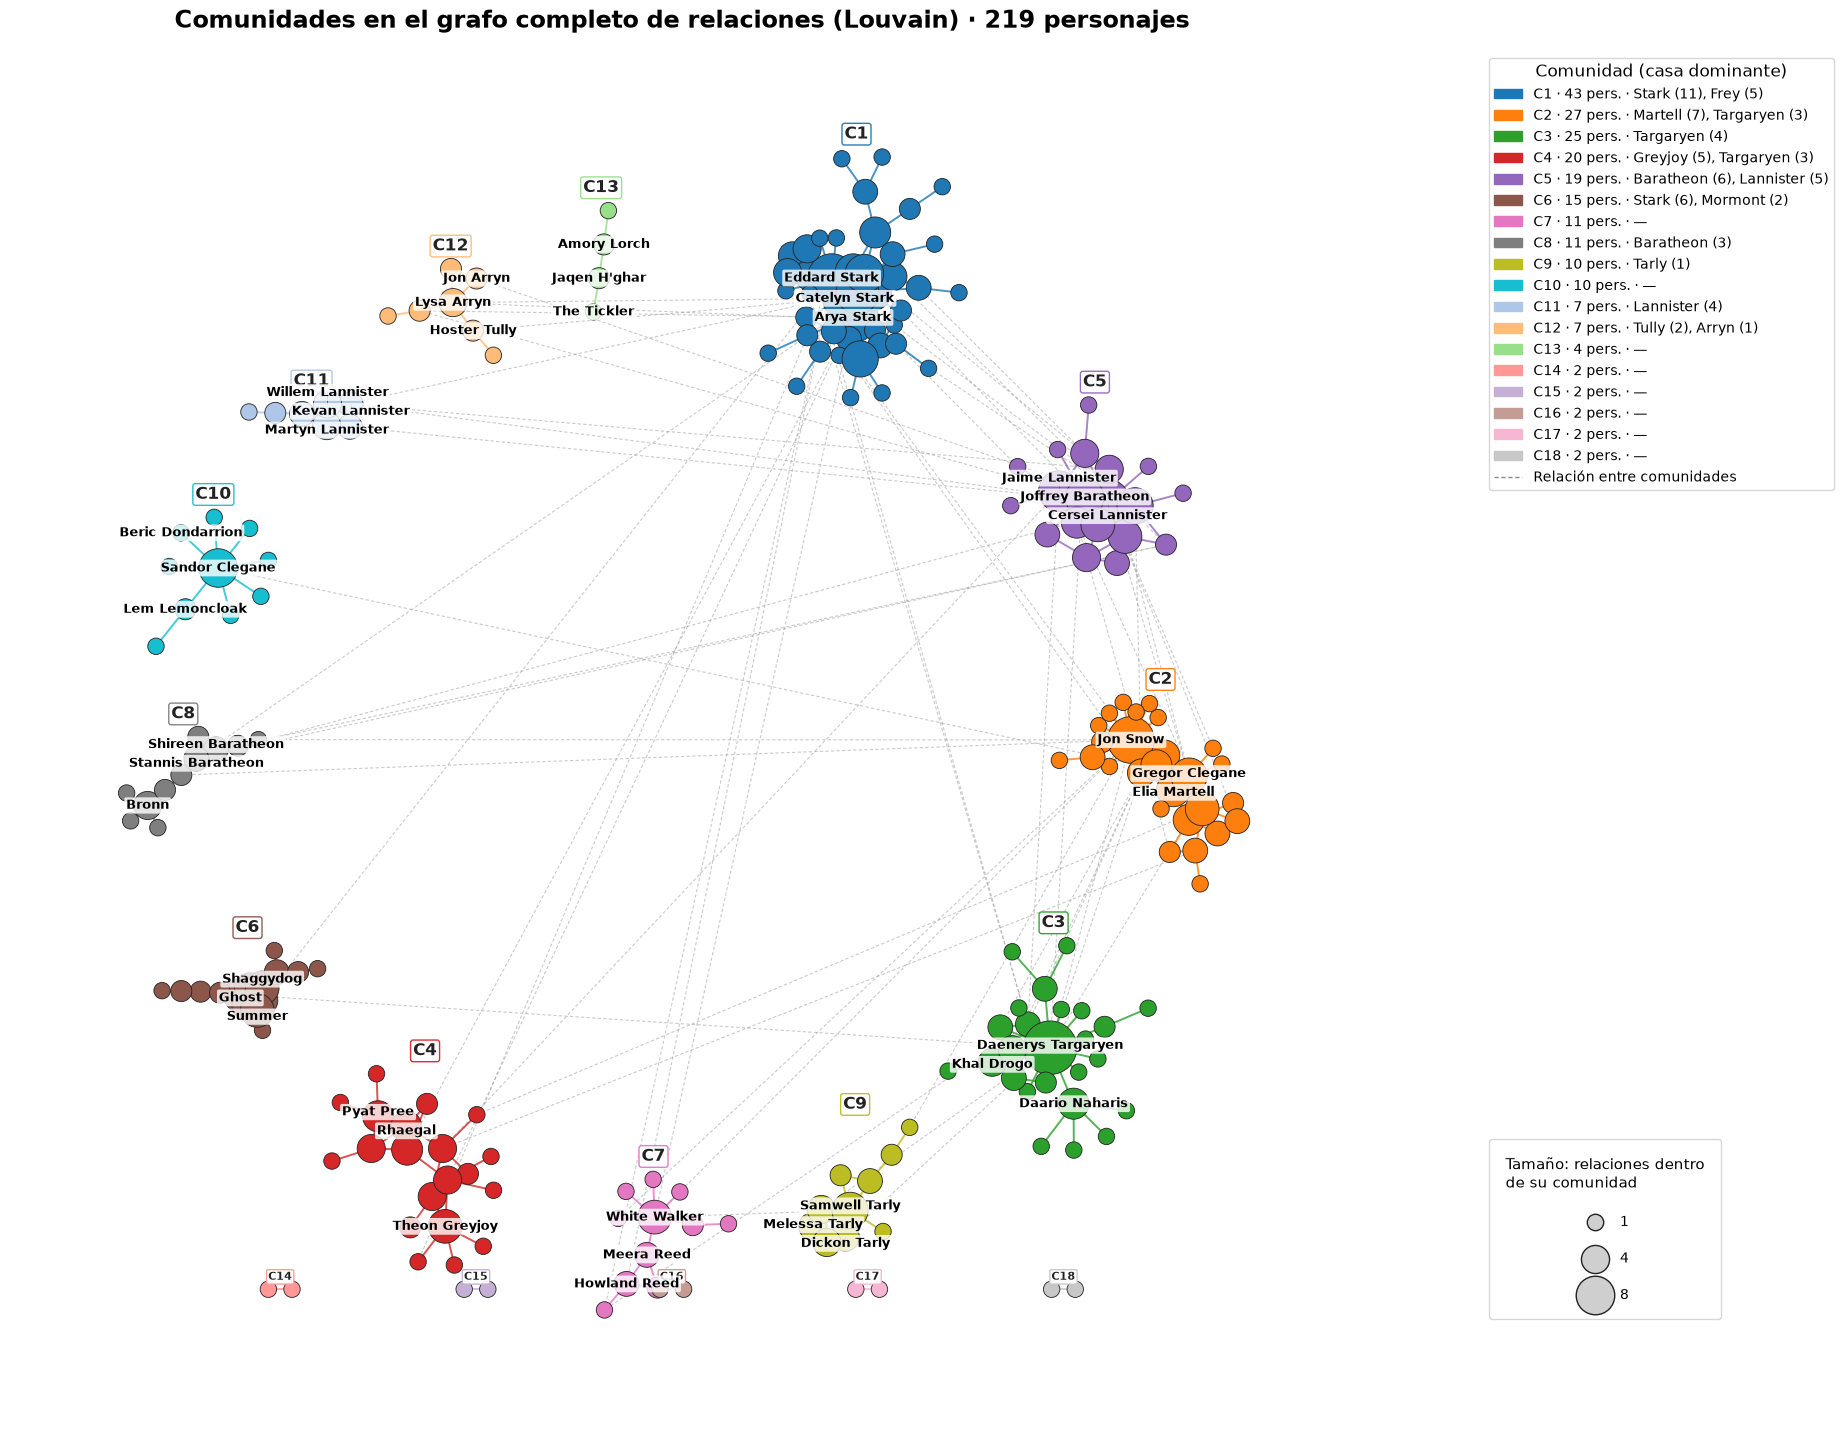

In [14]:
dibujar_comunidades(G_und, com_all, tabla_all,
                    f"Comunidades en el grafo completo de relaciones (Louvain) · {G_und.number_of_nodes()} personajes",
                    "1_3b_comunidades_grafo_completo")

**1. ¿Cuántas comunidades principales has identificado?**

En la **subred familiar** Louvain encuentra 19 comunidades (modularidad 0,794), de las cuales **9 son principales** (≥ 4 personajes); el resto son tríos o parejas sueltas (los Karstark, los Reed, los tres dragones…). En el **grafo completo** salen 18 comunidades con 13 principales (modularidad 0,709).

**2. ¿Coinciden estas comunidades con las casas nobles, alianzas o algún patrón que se pueda reconocer en la serie?**

En la subred familiar, **sí, casi una a una**: C1 Baratheon + Lannister de Desembarco (Robert, Cersei y sus hijos, con los Tyrell por el matrimonio de Margaery), C2 Frey + Tully + Arryn (casas unidas por matrimonios), C3 Targaryen (Rhaegar, Daenerys, Aerys… junto a Jon Snow, hijo de Rhaegar y Lyanna), C4 Stark, C5 Tarly, C6 Martell + Serpientes de Arena, C7 los **lobos huargos** de los Stark (que el dataset trata como hermanos), C8 Greyjoy y C9 la rama menor de los Lannister.

En el grafo completo, al añadir asesinatos y lealtades, las comunidades pasan a reflejar **tramas** más que casas: los Stark con los Frey (la Boda Roja y la venganza de Arya), Jon Snow con Rhaegar, Gregor Clegane, Elia y Oberyn Martell (el linaje de Rhaegar y la venganza de Dorne) y con los hermanos de la Guardia de la Noche que lo traicionan (Alliser Thorne, Olly), Daenerys con Daario y Viserys (Essos), Greyjoy con Qarth y los dragones, Cersei y Jaime en Desembarco, el White Walker con los Reed (la trama más allá del Muro), Stannis con Davos, Melisandre, Selyse y Shireen (la campaña de Stannis) o Sandor Clegane con la Hermandad sin Estandartes y sus víctimas del viaje por las Tierras de los Ríos. Es decir, **la familia agrupa por casas y los conflictos agrupan por tramas**.

**3. ¿Qué decisiones de diseño (colores, tamaño, layout) te han ayudado a mejorar la legibilidad del grafo?**

La más importante es el **layout en dos niveles**: con un `spring_layout` normal todas las comunidades quedaban apelotonadas en el centro y era imposible distinguirlas; colocando cada comunidad en su propia zona de una circunferencia (contiguas las que más se relacionan) cada grupo se lee como un bloque y las aristas entre comunidades se ven como "puentes". El **color** identifica la comunidad y los rótulos C1, C2, etc. permiten ubicar todos los grupos, incluidos los pequeños de la fila inferior. Dibujar las aristas internas del color de su comunidad y las externas en gris discontinuo separa la estructura interna de las conexiones entre grupos. Por último, el tamaño por grado dentro de la comunidad y etiquetar solo a los 3 personajes más conectados de cada una identifica a sus "líderes" sin saturar el gráfico; las etiquetas que se solapan se separan automáticamente.

# Parte 2: Visualización de datos geográficos con Folium

## Apartado 2.1: Preparar el mapa base de Juego de Tronos
Cargamos `land.geojson` (una única `MultiPolygon` con todos los continentes e islas) y los lugares. Unimos los dos ficheros de lugares: el ampliado (`places.geojson.json`), que contiene las regiones y mares, y el original del ZIP, del que solo falta *Highgarden* en el ampliado.

Funciones del mapa base:
- `calcular_limites`: recorre recursivamente las coordenadas del GeoJSON y devuelve la caja `[[lat_min, lon_min], [lat_max, lon_max]]`.
- `calcular_vista`: a partir de esa caja calcula el **centro** y el **zoom** inicial. Como Folium usa la proyección Web Mercator, la latitud se transforma con `y = ln(tan(π/4 + φ/2))` antes de calcular el punto medio y la extensión vertical; el zoom es el mayor nivel entero para el que la caja cabe en el tamaño del mapa en píxeles (a zoom *z* el mundo mide 256·2^z píxeles).
- `crear_mapa_base`: crea el mapa **sin teselas** (`tiles=None`), con mar, tierra, máscara, límites de navegación y título. Se reutiliza en 2.2 y 2.3.

In [15]:
with open(MAP_DIR / "land.geojson", encoding="utf-8") as f:
    land = json.load(f)


def cargar_lugares():
    ampliado = BASE / "places.geojson.json"
    if not ampliado.is_file():
        raise FileNotFoundError(f"Falta {ampliado.name}, que aporta las coordenadas de las regiones y mares.")
    lugares = {}
    for ruta in (MAP_DIR / "places.geojson", ampliado):   # el ampliado sobrescribe
        if ruta.exists():
            with open(ruta, encoding="utf-8") as f:
                for feat in json.load(f)["features"]:
                    lon, lat = feat["geometry"]["coordinates"]
                    lugares[feat["properties"]["name"]] = {"lat": lat, "lon": lon, "tipo": feat["properties"]["type"]}
    return pd.DataFrame.from_dict(lugares, orient="index")


lugares = cargar_lugares()
print(f"Lugares con coordenadas: {len(lugares)}")
lugares["tipo"].value_counts().to_frame().T

Lugares con coordenadas: 75


tipo,city,castle,region,ruin,sea,town
count,29,18,13,8,4,3


In [16]:
def calcular_limites(geojson):
    """Caja envolvente [[lat_min, lon_min], [lat_max, lon_max]] de cualquier GeoJSON."""
    lons, lats = [], []

    def recorrer(coords):
        if isinstance(coords[0], (int, float)):
            lons.append(coords[0])
            lats.append(coords[1])
        else:
            for c in coords:
                recorrer(c)

    for feat in geojson["features"]:
        recorrer(feat["geometry"]["coordinates"])
    return [[min(lats), min(lons)], [max(lats), max(lons)]]


def _merc(lat):
    return math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))


def _inv_merc(y):
    return math.degrees(2 * math.atan(math.exp(y)) - math.pi / 2)


def calcular_vista(limites, ancho_px=1000, alto_px=650, margen=0.03):
    """Centro y zoom para que la caja `limites` quepa en un mapa de ancho_px x alto_px (Web Mercator)."""
    (lat0, lon0), (lat1, lon1) = limites
    y0, y1 = _merc(lat0), _merc(lat1)
    centro = [_inv_merc((y0 + y1) / 2), (lon0 + lon1) / 2]
    frac_x = (lon1 - lon0) / 360                    # fracción del mundo en horizontal
    frac_y = (y1 - y0) / (2 * math.pi)              # fracción del mundo en vertical (Mercator)
    zoom_x = math.log2(ancho_px * (1 - margen) / (256 * frac_x))
    zoom_y = math.log2(alto_px * (1 - margen) / (256 * frac_y))
    return centro, int(math.floor(min(zoom_x, zoom_y)))


LIMITES = calcular_limites(land)
CENTRO, ZOOM = calcular_vista(LIMITES)
print("Límites (lat, lon):", np.round(LIMITES, 2).tolist())
print("Centro calculado:", np.round(CENTRO, 2).tolist(), "| Zoom inicial:", ZOOM)

Límites (lat, lon): [[-5.98, -58.26], [72.78, 131.17]]
Centro calculado: [45.41, 36.45] | Zoom inicial: 2


Diseño del mapa base:
- **Sin capa de teselas** (`tiles=None`): el mundo de Poniente no existe en ningún mapa real, superponer OpenStreetMap solo introduciría información falsa.
- **Mar:** un rectángulo azul grisáceo (`#a9c7d6`) del tamaño de la caja del GeoJSON. **Tierra:** color pergamino (`#efe3c2`) con borde marrón fino, que evoca los mapas de la serie y contrasta claramente con el mar.
- **Máscara:** el fondo del contenedor de Leaflet es un azul pizarra oscuro, por lo que todo lo que queda fuera del mundo de Juego de Tronos se ve como un marco oscuro sin información. Además, `max_bounds` impide desplazarse fuera de la caja y `min_zoom` impide alejarse más allá de la vista inicial.
- **Rótulos:** se muestran los nombres más útiles para orientarse a escala de todo el territorio. El resto se puede activar al ampliar el mapa.
- **Título** fijo en la parte superior con la tipografía *Cinzel* (de estilo medieval).

In [17]:
COLOR_MAR = "#a9c7d6"
COLOR_TIERRA = "#efe3c2"
COLOR_BORDE = "#8c7651"
COLOR_FUERA = "#1f2a36"
ANCHO_MAPA, ALTO_MAPA = 1000, 650
ROTULOS_GENERALES = {
    "North of the Wall", "The North", "The Iron Islands", "The Vale", "The Crownlands",
    "Dorne", "The Sunset Sea", "The Summer Sea", "The Shivering Sea", "The Dothraki Sea",
    "The Red Waste",
}


def dibujar_territorio(ax):
    """Dibuja la misma geometría y usa la misma proyección que el mapa interactivo."""
    from matplotlib.path import Path as MplPath
    from matplotlib.patches import PathPatch

    (lat0, lon0), (lat1, lon1) = LIMITES
    for feature in land["features"]:
        geometria = feature["geometry"]
        poligonos = geometria["coordinates"]
        if geometria["type"] == "Polygon":
            poligonos = [poligonos]
        for poligono in poligonos:
            anillos = [MplPath([(lon, mapa_y(lat)) for lon, lat in anillo], closed=True)
                       for anillo in poligono]
            ax.add_patch(PathPatch(MplPath.make_compound_path(*anillos),
                                    facecolor=COLOR_TIERRA, edgecolor=COLOR_BORDE, linewidth=0.45))
    ax.set_xlim(lon0 - 3, lon1 + 3)
    ax.set_ylim(mapa_y(lat0 - 2), mapa_y(lat1 + 2))
    ax.set_aspect("equal")
    ax.set_facecolor(COLOR_MAR)
    ax.set_xticks([])
    ax.set_yticks([])
    for borde in ax.spines.values():
        borde.set_visible(False)


def mapa_y(lat):
    return _merc(lat) * 180 / math.pi


def figura_mapa(titulo, subtitulo):
    fig, ax = plt.subplots(figsize=(11, 7))
    fig.subplots_adjust(left=0.03, right=0.97, top=0.88, bottom=0.15)
    fig.suptitle(titulo, fontsize=17, fontweight="bold", y=0.98)
    fig.text(0.5, 0.922, subtitulo, ha="center", color="#5b4a32")
    dibujar_territorio(ax)
    return fig, ax


def escala_pdf(fig, escala, caption):
    cmap = mpl.colors.LinearSegmentedColormap.from_list("mapa", escala.colors)
    valores = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(escala.vmin, escala.vmax), cmap=cmap)
    cax = fig.add_axes((0.31, 0.085, 0.38, 0.023))
    barra = fig.colorbar(valores, cax=cax, orientation="horizontal")
    ticks = mpl.ticker.MaxNLocator(nbins=5, integer=True).tick_values(escala.vmin, escala.vmax)
    margen = 0.08 * (escala.vmax - escala.vmin)
    interiores = [int(v) for v in ticks if escala.vmin + margen < v < escala.vmax - margen]
    barra.set_ticks([int(escala.vmin), *interiores, int(escala.vmax)])
    barra.set_label(caption, fontsize=10)


def anadir_titulo(mapa, titulo, subtitulo=""):
    html = f"""
    <link href="https://fonts.googleapis.com/css2?family=Cinzel:wght@600;700&display=swap" rel="stylesheet">
    <div style="position:absolute; top:10px; left:56px; z-index:9999; max-width:430px;
                background:rgba(250,245,230,0.92); border:1px solid {COLOR_BORDE}; border-radius:6px;
                padding:6px 18px; text-align:center; box-shadow:0 1px 4px rgba(0,0,0,0.3);">
      <div style="font-family:'Cinzel',serif; font-size:20px; font-weight:700; color:#3b2f1e;">{titulo}</div>
      {f'<div style="font-family:Georgia,serif; font-size:12px; color:#5b4a32;">{subtitulo}</div>' if subtitulo else ''}
    </div>"""
    mapa.get_root().html.add_child(Element(html))


def crear_mapa_base(titulo="Mapa de los Siete Reinos y Essos", subtitulo="", rotulos=True, rotulos_visibles=True):
    (lat0, lon0), (lat1, lon1) = LIMITES
    m = folium.Map(location=CENTRO, zoom_start=ZOOM, min_zoom=ZOOM, max_zoom=ZOOM + 4,
                   tiles=None, width=ANCHO_MAPA, height=ALTO_MAPA, control_scale=False,
                   max_bounds=True, min_lat=lat0 - 3, max_lat=lat1 + 3, min_lon=lon0 - 5, max_lon=lon1 + 5,
                   zoom_snap=0.25)
    # Máscara: fondo oscuro fuera del mundo de GoT. Fondo claro para la leyenda de las escalas de color.
    m.get_root().header.add_child(Element(
        f"<style>.leaflet-container {{ background: {COLOR_FUERA} !important; }}"
        f".legend {{ background: rgba(250,245,230,0.92); border:1px solid {COLOR_BORDE}; border-radius:6px;"
        f" padding:2px 6px 0 2px; box-shadow:0 1px 4px rgba(0,0,0,0.3); }}</style>"))

    # Mar (caja del GeoJSON con un pequeño margen)
    folium.Rectangle(bounds=[[lat0 - 2, lon0 - 3], [lat1 + 2, lon1 + 3]], color=None, weight=0,
                     fill=True, fill_color=COLOR_MAR, fill_opacity=1, interactive=False).add_to(m)
    # Tierra
    folium.GeoJson(land, name="Territorio", control=False,
                   style_function=lambda _: {"fillColor": COLOR_TIERRA, "fillOpacity": 1,
                                             "color": COLOR_BORDE, "weight": 0.8},
                   interactive=False).add_to(m)

    if rotulos:
        regiones = lugares[lugares["tipo"].isin(["region", "sea"])]
        for nombre_capa, seleccion, visible in (
            ("Rótulos de orientación", regiones.index.isin(ROTULOS_GENERALES), rotulos_visibles),
            ("Otros rótulos de regiones y mares", ~regiones.index.isin(ROTULOS_GENERALES), False),
        ):
            capa = folium.FeatureGroup(name=nombre_capa, show=visible)
            for nombre, fila in regiones[seleccion].iterrows():
                estilo = "color:#2f5d7c;" if fila["tipo"] == "sea" else "color:#6b5a3e;"
                folium.Marker([fila["lat"], fila["lon"]], interactive=False, icon=folium.DivIcon(
                    class_name="rotulo-mapa", icon_size=(160, 17), icon_anchor=(80, -3),
                    html='<div style="font:italic 11px Georgia;text-align:center;'
                         f'{estilo}text-shadow:0 0 3px #fff;">{nombre}</div>')).add_to(capa)
            capa.add_to(m)

    m.fit_bounds(LIMITES)
    anadir_titulo(m, titulo, subtitulo)
    return m


titulo_base = "Mapa de los Siete Reinos y Essos"
subtitulo_base = "Territorio de Poniente y Essos según land.geojson"
mapa_base = crear_mapa_base(titulo_base, subtitulo_base)
folium.LayerControl(collapsed=False).add_to(mapa_base)

fig, ax = figura_mapa(titulo_base, subtitulo_base)
for nombre, lugar in lugares[lugares.index.isin(ROTULOS_GENERALES)].iterrows():
    borde_oeste = lugar["lon"] < LIMITES[0][1] + 5
    ax.annotate(nombre, (lugar["lon"], mapa_y(lugar["lat"])), xytext=(3 if borde_oeste else 0, 2),
                textcoords="offset points", ha="left" if borde_oeste else "center", fontsize=8,
                fontstyle="italic",
                color="#2f5d7c" if lugar["tipo"] == "sea" else "#5b4a32",
                bbox=dict(fc="#fffaf0", ec="none", alpha=0.85, pad=0.7))
exportar_mapa(mapa_base, "2_1_mapa_base", fig)
mapa_base

Mapa exportado: 2_1_mapa_base.html y 2_1_mapa_base.pdf


**¿Qué capa base (tiles) has utilizado y por qué?**

Ninguna (`tiles=None`). Cualquier capa real (OpenStreetMap, CartoDB…) mostraría costas, países y nombres del mundo real que no tienen relación con Poniente y confundirían al lector. El "mapa base" lo construimos nosotros con dos capas vectoriales: un rectángulo de mar y el GeoJSON de tierra.

**¿Cómo has definido los colores o estilos para distinguir tierra y mar?**

Mar en azul grisáceo desaturado (`#a9c7d6`) y tierra en color pergamino (`#efe3c2`) con un borde marrón fino (`#8c7651`): hay mucho contraste de luminosidad y tono, se reconoce enseguida qué es agua y qué es tierra, y recuerda al mapa de la cabecera de la serie. Los colores son suaves a propósito, porque en 2.2 y 2.3 encima irán marcadores de colores intensos que deben destacar. Fuera de la caja del mundo, el fondo es un azul pizarra muy oscuro que actúa como máscara.

**¿Cómo has implementado la función para obtener los valores para ajustar el zoom y centro del mapa?**

`calcular_limites` recorre recursivamente todas las coordenadas del GeoJSON (sirve para Polygon, MultiPolygon, etc.) y obtiene la latitud/longitud mínimas y máximas. `calcular_vista` transforma las latitudes a Web Mercator (que es la proyección que usa Leaflet), calcula el centro como el punto medio en esa proyección y el zoom como `floor(log2(píxeles_disponibles / (256 · fracción_del_mundo)))` en cada eje, quedándose con el menor. Ese zoom se usa como `zoom_start` y como `min_zoom`, los límites se usan en `max_bounds` y, además, `fit_bounds` ajusta el encuadre final al tamaño real del contenedor.

## Apartado 2.2: Mostrar la importancia de cada ubicación

### 1. Recuento de episodios por localización
Cada escena de `episodes.json` tiene un campo `location` (región o ciudad principal, p. ej. *The Crownlands*) y casi siempre un `subLocation` más concreto (p. ej. *King's Landing*). Todos los valores de `location` existen en el fichero de lugares ampliado, y 20 de los `subLocation` también (castillos y ciudades). Por eso trabajamos con **dos niveles**:
- **Regiones** (`location`): cobertura completa de todas las escenas.
- **Ciudades y castillos** (`subLocation` con coordenadas): ubicaciones más precisas.

Para cada lugar calculamos: episodios en los que aparece (dato principal), número de escenas, minutos en pantalla, temporadas, primera aparición, sublugares más frecuentes y personajes más frecuentes.

In [18]:
with open(DATA_DIR / "episodes.json", encoding="utf-8") as f:
    episodes = json.load(f)["episodes"]


def a_segundos(t):
    h, m, s = (int(x) for x in t.split(":"))
    return 3600 * h + 60 * m + s


# Tabla "larga": una fila por escena
filas = []
for ep in episodes:
    for i, esc in enumerate(ep["scenes"]):
        filas.append({
            "temporada": ep["seasonNum"], "episodio": ep["episodeNum"], "titulo": ep["episodeTitle"],
            "id_ep": f"T{ep['seasonNum']}E{ep['episodeNum']:02d}", "orden": i,
            "location": esc["location"], "subLocation": esc.get("subLocation") or "",
            "duracion": a_segundos(esc["sceneEnd"]) - a_segundos(esc["sceneStart"]),
            "personajes": [c["name"] for c in esc["characters"]],
        })
escenas = pd.DataFrame(filas)
sin_coordenadas = set(escenas["location"]) - set(lugares.index)
if sin_coordenadas:
    raise ValueError(f"Faltan coordenadas para estas localizaciones: {', '.join(sorted(sin_coordenadas))}")
print(f"{len(episodes)} episodios · {len(escenas)} escenas · {escenas['location'].nunique()} localizaciones · "
      f"{escenas['subLocation'].nunique()} sublocalizaciones")


def resumen_lugares(df, campo):
    """Estadísticas por lugar para el nivel indicado ('location' o 'subLocation')."""
    filas = []
    for lugar, g in df.groupby(campo):
        if lugar not in lugares.index:
            continue
        primera = g.sort_values(["temporada", "episodio", "orden"]).iloc[0]
        subl = Counter(s for s in g["subLocation"] if s and s != lugar)
        pers = Counter(p for ps in g["personajes"] for p in ps)
        filas.append({
            "lugar": lugar, "tipo": lugares.at[lugar, "tipo"],
            "lat": lugares.at[lugar, "lat"], "lon": lugares.at[lugar, "lon"],
            "episodios": g["id_ep"].nunique(), "escenas": len(g),
            "minutos": round(g["duracion"].sum() / 60),
            "temporadas": ", ".join(str(t) for t in sorted(g["temporada"].unique())),
            "primera": f"{primera['id_ep']} · {primera['titulo']}",
            "sublugares": ", ".join(s for s, _ in subl.most_common(5)),
            "personajes": ", ".join(p for p, _ in pers.most_common(5)),
        })
    return pd.DataFrame(filas).sort_values("episodios", ascending=False).reset_index(drop=True)


stats_region = resumen_lugares(escenas, "location")
stats_ciudad = resumen_lugares(escenas, "subLocation")
display(stats_region[["lugar", "tipo", "episodios", "escenas", "minutos", "temporadas"]].head(12))
display(stats_ciudad[["lugar", "tipo", "episodios", "escenas", "minutos", "temporadas"]].head(12))

73 episodios · 4165 escenas · 26 localizaciones · 97 sublocalizaciones


,lugar,tipo,episodios,escenas,minutos,temporadas
0,The Crownlands,region,64,1377,1299,"1, 2, 3, 4, 5, 6, 7, 8"
1,The North,region,54,979,734,"1, 2, 3, 4, 5, 6, 7, 8"
2,The Wall,region,36,331,313,"1, 3, 4, 5, 6, 7, 8"
3,North of the Wall,region,35,364,284,"1, 2, 3, 4, 5, 6, 7, 8"
4,The Riverlands,region,33,315,389,"1, 2, 3, 4, 6, 7"
5,Meereen,city,24,184,199,"4, 5, 6"
6,Braavos,city,14,103,100,"4, 5, 6"
7,The Vale,region,11,56,90,"1, 4, 5, 6"
8,Dorne,region,10,50,49,"5, 6, 7"
9,The Westerlands,region,9,46,59,"1, 2, 5, 7"


,lugar,tipo,episodios,escenas,minutos,temporadas
0,King's Landing,city,63,1094,1018,"1, 2, 3, 4, 5, 6, 7, 8"
1,Winterfell,castle,42,734,504,"1, 2, 5, 6, 7, 8"
2,Castle Black,castle,30,267,272,"1, 3, 4, 5, 6, 8"
3,Dragonstone,castle,20,142,187,"2, 3, 4, 7, 8"
4,Harrenhal,castle,10,50,61,"2, 3"
5,The Wall,region,10,60,26,"2, 3, 4, 5, 7, 8"
6,The Dreadfort,castle,8,34,44,"3, 4"
7,Pyke,castle,6,27,33,"2, 3, 6"
8,Riverrun,castle,6,47,51,"1, 3, 6"
9,The Twins,castle,6,57,47,"1, 3, 6, 7"


### 2. Mapa de importancia
Decisiones de diseño:
- **Marcadores:** `CircleMarker`, cuyo radio está en **píxeles** (no en metros), de modo que el tamaño no depende de la latitud (en Mercator un círculo de *X* km en el Norte se vería mucho más grande que en Essos) y se mantiene legible con cualquier zoom.
- **Tamaño:** el radio crece con la **raíz cuadrada** del número de episodios y alcanza un máximo de 22 px. El radio mínimo evita que desaparezcan los puntos de menor frecuencia. Así, *The Crownlands* (presente en casi todos los episodios) no tapa el mapa y los lugares de 1–2 episodios siguen viéndose.
- **Color:** escala secuencial `YlOrRd` (amarillo → rojo oscuro) sobre el número de episodios, con leyenda: el tono más intenso refuerza al tamaño. Las regiones/mares se dibujan con borde continuo y las ciudades/castillos con borde blanco más grueso para distinguir el nivel.
- **Solapamientos:** los círculos se dibujan de mayor a menor para que los pequeños queden encima y sean clicables, con relleno semitransparente. Los dos niveles van en **capas activables** (`LayerControl`). La vista inicial muestra las regiones. Las ciudades y los castillos se pueden activar al ampliar, y una tercera capa muestra los lugares sin apariciones registradas. Los rótulos de regiones del mapa base también se ocultan por defecto (se pueden activar) para que no tapen los círculos.
- **Tooltip** (al pasar el ratón): nombre y episodios. **Popup** (al hacer clic): ficha completa.

In [19]:
max_ep = max(stats_region["episodios"].max(), stats_ciudad["episodios"].max())
escala_color = bcm.LinearColormap(["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"],
                                  vmin=1, vmax=max_ep, caption="Número de episodios en los que aparece la localización")


def radio(n, rmin=4, rmax=22):
    return rmin + (rmax - rmin) * math.sqrt(n / max_ep)


def popup_lugar(f, nivel):
    filas = [("Tipo", f["tipo"]), ("Nivel", nivel), ("Episodios", f"<b>{f['episodios']}</b> de {len(episodes)}"),
             ("Escenas", f["escenas"]), ("Tiempo en pantalla", f"{f['minutos']} min"),
             ("Temporadas", f["temporadas"]), ("Primera aparición", f["primera"]),
             ("Sublugares frecuentes", f["sublugares"] or "—"), ("Personajes frecuentes", f["personajes"])]
    cuerpo = "".join(f"<tr><td style='color:#6b5a3e;padding-right:8px;vertical-align:top'>{k}</td><td>{v}</td></tr>"
                     for k, v in filas)
    html = (f"<div style='font-family:Georgia,serif;font-size:12px;width:300px'>"
            f"<h4 style='margin:0 0 6px 0;font-family:Cinzel,serif'>{f['lugar']}</h4><table>{cuerpo}</table></div>")
    return folium.Popup(html, max_width=330)


def anadir_circulos(df, capa, nivel, borde, grosor):
    for _, f in df.sort_values("episodios", ascending=False).iterrows():
        folium.CircleMarker(
            location=[f["lat"], f["lon"]], radius=radio(f["episodios"]),
            color=borde, weight=grosor, fill=True, fill_color=escala_color(f["episodios"]), fill_opacity=0.8,
            tooltip=f"<b>{f['lugar']}</b><br>{f['episodios']} episodios · {f['escenas']} escenas",
            popup=popup_lugar(f, nivel),
        ).add_to(capa)


mapa_importancia = crear_mapa_base("Importancia de las localizaciones",
                                   "Tamaño y color: número de episodios en los que aparece cada lugar",
                                   rotulos_visibles=False)

capa_reg = folium.FeatureGroup(name="Regiones y mares (location)", show=True)
anadir_circulos(stats_region, capa_reg, "Región / localización principal", "#5b4a32", 1)
capa_reg.add_to(mapa_importancia)

capa_ciu = folium.FeatureGroup(name="Ciudades y castillos (subLocation)", show=False)
anadir_circulos(stats_ciudad, capa_ciu, "Ciudad / castillo (sublocalización)", "#ffffff", 2)
capa_ciu.add_to(mapa_importancia)

capa_nunca = folium.FeatureGroup(name="Lugares sin apariciones registradas", show=False)
con_apariciones = set(stats_region["lugar"]) | set(stats_ciudad["lugar"])
for nombre, f in lugares[~lugares.index.isin(con_apariciones)].iterrows():
    folium.CircleMarker([f["lat"], f["lon"]], radius=3, color="#777777", weight=1, fill=True,
                        fill_color="#bbbbbb", fill_opacity=0.9,
                        tooltip=f"{nombre} ({f['tipo']}) · sin apariciones en los campos analizados").add_to(capa_nunca)
capa_nunca.add_to(mapa_importancia)

escala_color.add_to(mapa_importancia)
folium.LayerControl(collapsed=False, position="topright").add_to(mapa_importancia)
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
fig.subplots_adjust(left=0.025, right=0.975, bottom=0.19, top=0.84, wspace=0.06)
fig.suptitle("Importancia de las localizaciones", fontsize=17, fontweight="bold")
for ax, datos, nombre, borde in (
    (axs[0], stats_region, "Regiones y localizaciones principales", "#5b4a32"),
    (axs[1], stats_ciudad, "Ciudades y castillos", "white"),
):
    dibujar_territorio(ax)
    ax.set_title(nombre, fontsize=12)
    for _, f in datos.sort_values("episodios", ascending=False).iterrows():
        ax.scatter(f["lon"], mapa_y(f["lat"]), s=(0.9 * radio(f["episodios"])) ** 2 * 2,
                   c=escala_color(f["episodios"]), edgecolors=borde, linewidths=0.65, alpha=0.85)
escala_pdf(fig, escala_color, "Número de episodios en los que aparece la localización")
exportar_mapa(mapa_importancia, "2_2_importancia_localizaciones", fig)
mapa_importancia

Mapa exportado: 2_2_importancia_localizaciones.html y 2_2_importancia_localizaciones.pdf


**¿Qué criterio has seguido para definir el tamaño y color de los círculos?**

Ambos codifican el **número de episodios** en los que aparece el lugar (redundancia intencionada: el color ayuda cuando dos círculos tienen tamaños parecidos). El radio crece con la **raíz cuadrada** del número de episodios hasta 22 píxeles. Se añade un mínimo de lectura, por lo que el área solo es aproximadamente proporcional al recuento. El color usa una escala secuencial `YlOrRd`, perceptualmente ordenada: amarillo pálido para los lugares anecdóticos y rojo oscuro para los centrales (*The Crownlands*/*King's Landing*, *The North*/*Winterfell*, *The Wall*). El borde (oscuro para regiones, blanco para ciudades y castillos) distingue los dos niveles de detalle.

**¿Qué información has decidido incluir en los popups y por qué?**

En el **tooltip**, lo mínimo para explorar rápido: nombre, episodios y escenas. En el **popup**, una ficha con: tipo de lugar, nivel, episodios (sobre el total de 73), escenas, minutos en pantalla, temporadas en las que aparece, primera aparición, sublugares más frecuentes y personajes más frecuentes. Episodios, escenas y minutos miden la importancia de forma complementaria (un lugar puede salir en muchos episodios con escenas muy cortas); las temporadas y la primera aparición sitúan el lugar en la cronología; y los sublugares y personajes explican *qué* pasa allí.

**¿Qué tipo de capa o fondo permite visualizar mejor la distribución de los puntos?**

Un fondo **sin teselas**, con colores planos y apagados (mar azul grisáceo y tierra pergamino), porque no compite con los marcadores y el color de la escala se lee sin interferencias. Separar regiones y ciudades en **capas activables** permite ver cada nivel por separado cuando se solapan (por ejemplo, *The Crownlands* y *King's Landing*), y la capa oculta de lugares sin apariciones registradas permite compararlos con los lugares contabilizados sin saturar la vista inicial.

## Apartado 2.3: Visualizar la ruta de lugares en un episodio
El episodio se elige con las variables `TEMPORADA` y `EPISODIO`. Para cada escena usamos su `location` (que siempre tiene coordenadas) y guardamos su `subLocation`. Las escenas consecutivas en el mismo lugar se agrupan en una única **parada**, de modo que la ruta es la secuencia de cambios de lugar.

Decisiones de diseño:
- **Marcadores numerados** (`DivIcon` circular) con el **orden** de la parada. Si se vuelve a un lugar varias veces, en el mismo marcador aparecen todos los números (p. ej. `2·5·9`) en lugar de apilar marcadores ilegibles.
- **Tamaño del marcador** creciente con el número de escenas y con el espacio necesario para mostrar todas sus paradas.
- **Trayectos** con **color según el orden cronológico** (escala `viridis`: morado al inicio del episodio → amarillo al final), **flechas** de dirección sobre la línea y **curvatura**: las líneas se curvan siempre hacia el mismo lado respecto a su sentido, así que un ida y vuelta A→B y B→A se dibuja como dos arcos separados en vez de una sola línea superpuesta. Cada repetición en el mismo sentido usa un arco más curvo, de modo que sus colores cronológicos se distinguen. El grosor aumenta con el número de repeticiones.
- **Tooltips y popups** en lugares y trayectos con nombre, sublugares, apariciones, etc.

In [20]:
# ---- Parámetros: episodio a representar ----
TEMPORADA = 6
EPISODIO = 10


def extraer_ruta(temporada, episodio):
    ep = next((e for e in episodes if e["seasonNum"] == temporada and e["episodeNum"] == episodio), None)
    if ep is None:
        raise ValueError(f"No existe el episodio T{temporada}E{episodio}")
    paradas = []
    for esc in ep["scenes"]:
        lugar, sub = esc["location"], esc.get("subLocation") or ""
        if paradas and paradas[-1]["lugar"] == lugar:
            p = paradas[-1]
        else:
            p = {"lugar": lugar, "sublugares": [], "escenas": 0, "duracion": 0, "personajes": Counter()}
            paradas.append(p)
        p["escenas"] += 1
        p["duracion"] += a_segundos(esc["sceneEnd"]) - a_segundos(esc["sceneStart"])
        p["personajes"].update(c["name"] for c in esc["characters"])
        if sub and sub not in p["sublugares"]:
            p["sublugares"].append(sub)
    for i, p in enumerate(paradas, start=1):
        p["orden"] = i
    return ep, paradas


def puntos_arco(a, b, curvatura=0.18, n=24):
    """Curva cuadrática de Bézier entre a y b, desplazada a la izquierda del sentido de avance."""
    (la, lo_a), (lb, lo_b) = a, b
    dx, dy = lo_b - lo_a, lb - la
    control = ((la + lb) / 2 + curvatura * dx, (lo_a + lo_b) / 2 - curvatura * dy)
    return [((1 - t) ** 2 * la + 2 * (1 - t) * t * control[0] + t ** 2 * lb,
             (1 - t) ** 2 * lo_a + 2 * (1 - t) * t * control[1] + t ** 2 * lo_b)
            for t in np.linspace(0, 1, n)]


def mapa_ruta_episodio(temporada, episodio, nombre_salida=None):
    ep, paradas = extraer_ruta(temporada, episodio)
    n = len(paradas)
    escala = bcm.LinearColormap(["#440154", "#3b528b", "#21918c", "#5ec962", "#fde725"], vmin=1, vmax=max(n - 1, 2),
                                caption="Orden del trayecto en el episodio (inicio → final)")

    # Agregar por lugar
    por_lugar = defaultdict(lambda: {"ordenes": [], "sublugares": [], "escenas": 0, "duracion": 0, "personajes": Counter()})
    for p in paradas:
        L = por_lugar[p["lugar"]]
        L["ordenes"].append(p["orden"])
        L["escenas"] += p["escenas"]
        L["duracion"] += p["duracion"]
        L["personajes"].update(p["personajes"])
        L["sublugares"] += [s for s in p["sublugares"] if s not in L["sublugares"]]

    tramos = Counter((a["lugar"], b["lugar"]) for a, b in zip(paradas, paradas[1:]))
    recorridos = Counter()
    titulo = f"T{temporada}E{episodio:02d} · {ep['episodeTitle']}"
    subtitulo = f"{len(ep['scenes'])} escenas · {n} paradas · {len(por_lugar)} lugares distintos"
    m = crear_mapa_base(titulo, subtitulo, rotulos=False)
    if nombre_salida is not None:
        fig, ax = figura_mapa(titulo, subtitulo)
        escala_pdf(fig, escala, "Orden del trayecto en el episodio")

    # --- Trayectos (aristas) ---
    capa_tray = folium.FeatureGroup(name="Trayectos", show=True)
    for i, (a, b) in enumerate(zip(paradas, paradas[1:]), start=1):
        pa = (lugares.at[a["lugar"], "lat"], lugares.at[a["lugar"], "lon"])
        pb = (lugares.at[b["lugar"], "lat"], lugares.at[b["lugar"], "lon"])
        color = escala(i)
        par = a["lugar"], b["lugar"]
        veces = tramos[par]
        recorridos[par] += 1
        ancho = min(2.5 + 0.85 * veces, 5)
        paso_curvatura = min(0.24, 0.72 / max(1, veces - 1))
        curva = puntos_arco(pa, pb, curvatura=0.18 + paso_curvatura * (recorridos[par] - 1))
        if nombre_salida is not None:
            xy = [(lon, mapa_y(lat)) for lat, lon in curva]
            ax.plot(*zip(*xy), color=color, linewidth=0.48 * ancho, alpha=0.9)
            origen, destino = xy[11], xy[13]
            ax.annotate("", xy=destino, xytext=origen,
                        arrowprops=dict(arrowstyle="-|>", color=color, lw=1, mutation_scale=10,
                                        shrinkA=0, shrinkB=0))
        info = (f"<b>Trayecto {i}:</b> {a['lugar']} → {b['lugar']}<br>"
                f"<b>Parada {a['orden']} → {b['orden']}</b><br>"
                f"<b>Sublugares origen:</b> {', '.join(a['sublugares']) or '—'}<br>"
                f"<b>Sublugares destino:</b> {', '.join(b['sublugares']) or '—'}<br>"
                f"<b>Veces que se repite este trayecto:</b> {veces}<br>"
                f"<b>Apariciones en el episodio:</b> {a['lugar']} {por_lugar[a['lugar']]['escenas']} escenas, "
                f"{b['lugar']} {por_lugar[b['lugar']]['escenas']} escenas")
        linea = folium.PolyLine(curva, color=color, weight=ancho, opacity=0.9,
                                tooltip=f"Trayecto {i}: {a['lugar']} → {b['lugar']}",
                                popup=folium.Popup(f"<div style='font-family:Georgia;font-size:12px;width:280px'>{info}</div>",
                                                   max_width=300))
        linea.add_to(capa_tray)
        plugins.PolyLineTextPath(linea, "  ►  ", repeat=True, offset=5,
                                 attributes={"fill": color, "font-size": "13", "stroke": "#333",
                                             "stroke-width": "0.4"}).add_to(capa_tray)
    capa_tray.add_to(m)

    # --- Lugares (nodos) ---
    capa_lug = folium.FeatureGroup(name="Lugares visitados", show=True)
    for lugar, L in por_lugar.items():
        lat, lon = lugares.at[lugar, "lat"], lugares.at[lugar, "lon"]
        ordenes = L["ordenes"]
        lista_paradas = "·".join(map(str, ordenes))
        etiqueta = lista_paradas if len(ordenes) <= 6 else f"{ordenes[0]}·…·{ordenes[-1]}"
        diam = int(22 + 3 * math.sqrt(L["escenas"])) + 5 * (min(len(ordenes), 6) - 1)
        color = escala(min(L["ordenes"][0], max(n - 1, 2)))
        color_texto = "#000" if L["ordenes"][0] > n * 0.6 else "#fff"
        if nombre_salida is not None:
            texto = ax.annotate(etiqueta, (lon, mapa_y(lat)), ha="center", va="center",
                                color=color_texto, fontsize=8, fontweight="bold", zorder=10,
                                bbox=dict(boxstyle=f"round,pad={0.22 + 0.04 * math.sqrt(L['escenas'])}",
                                          fc=color, ec="white", lw=1.2))
            texto.set_in_layout(False)
        icono = folium.DivIcon(class_name="marcador-ruta", icon_size=(diam + 30, diam),
                               icon_anchor=((diam + 30) // 2, diam // 2), html=f"""
            <div style="display:flex; justify-content:center;">
              <div style="min-width:{diam}px; height:{diam}px; padding:0 4px; border-radius:{diam}px;
                          background:{color}; border:2px solid #fff; box-shadow:0 0 4px rgba(0,0,0,.6);
                          color:{color_texto}; font:bold 12px Arial;
                          display:flex; align-items:center; justify-content:center;">{etiqueta}</div></div>""")
        principales = ", ".join(p for p, _ in L["personajes"].most_common(5))
        info = (f"<h4 style='margin:0 0 4px 0;font-family:Cinzel,serif'>{lugar}</h4>"
                f"<b>Orden de aparición:</b> {', '.join(map(str, L['ordenes']))}<br>"
                f"<b>Veces que aparece:</b> {len(L['ordenes'])} visita(s), {L['escenas']} escenas<br>"
                f"<b>Tiempo en pantalla:</b> {L['duracion'] // 60} min {L['duracion'] % 60} s<br>"
                f"<b>Sublugares:</b> {', '.join(L['sublugares']) or '—'}<br>"
                f"<b>Personajes principales:</b> {principales}")
        folium.Marker([lat, lon], icon=icono,
                      tooltip=f"<b>{lugar}</b> · paradas {lista_paradas} · {L['escenas']} escenas",
                      popup=folium.Popup(f"<div style='font-family:Georgia;font-size:12px;width:290px'>{info}</div>",
                                         max_width=310)).add_to(capa_lug)
    capa_lug.add_to(m)

    escala.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    if nombre_salida is not None:
        exportar_mapa(m, nombre_salida, fig)
    return m, paradas


mapa_ruta, paradas = mapa_ruta_episodio(TEMPORADA, EPISODIO, f"2_3_ruta_T{TEMPORADA}E{EPISODIO:02d}")
display(pd.DataFrame([{"parada": p["orden"], "lugar": p["lugar"], "escenas": p["escenas"],
                       "sublugares": ", ".join(p["sublugares"])} for p in paradas]).set_index("parada"))
mapa_ruta

Mapa exportado: 2_3_ruta_T6E10.html y 2_3_ruta_T6E10.pdf


,lugar,escenas,sublugares
parada,,,
1,The Crownlands,55,King's Landing
2,The Riverlands,5,The Twins
3,The Crownlands,1,King's Landing
4,The Reach,4,Oldtown
5,The North,5,Winterfell
6,Dorne,2,The Water Gardens
7,Meereen,2,
8,The Riverlands,2,The Twins
9,The North,1,Winterfell


Para comprobar que el parámetro funciona, generamos también la ruta de otro episodio con muchos cambios de lugar: **T2E05 – *The Ghost of Harrenhal*** (14 paradas, 7 lugares).

In [21]:
mapa_ruta_2, _ = mapa_ruta_episodio(2, 5, "2_3_ruta_T2E05")
mapa_ruta_2

Mapa exportado: 2_3_ruta_T2E05.html y 2_3_ruta_T2E05.pdf


**¿Qué decisiones de diseño has tomado para mejorar la visualización del seguimiento de las rutas en los episodios?**

- **Orden cronológico:** se codifica de tres formas complementarias: el **número** de cada parada en el marcador, el **color** de los trayectos (escala secuencial *viridis*, perceptualmente uniforme y apta para daltónicos, de morado al principio a amarillo al final) y las **flechas** `►` que indican el sentido de cada trayecto.
- **Lugares repetidos:** en lugar de apilar marcadores en el mismo punto, un único marcador reúne las paradas (`2·5·9`) y se ensancha. Las secuencias muy largas se abrevian en el marcador y se pueden consultar completas en el tooltip y el popup. Su color es el de su primera aparición.
- **Idas, vueltas y repeticiones:** los sentidos opuestos van por arcos en lados distintos. Si se repite el mismo sentido, cada arco tiene más curvatura que el anterior y conserva su color cronológico. El grosor aumenta según la frecuencia del trayecto, con un límite para evitar que domine el mapa.
- **Número de apariciones:** el tamaño del marcador crece con las escenas situadas en ese lugar y con el número de paradas que debe mostrar.
- **Legibilidad:** se ocultan los rótulos de regiones del mapa base para no competir con los números, los marcadores llevan borde blanco y sombra para separarse del fondo, y el título del mapa incluye el episodio y un resumen (escenas, paradas, lugares).
- **Interactividad:** tooltips breves al pasar el ratón y popups con el detalle (sublugares de origen y destino, repeticiones del trayecto, personajes principales). Trayectos y lugares van en capas separadas para poder ocultarlos.

# Parte 3 (opcional): Visualización de grafos con PyVis
*Esta parte es opcional y no se evalúa.* Exportamos el grafo de relaciones de la Parte 1 a PyVis para obtener una visualización interactiva basada en un sistema de fuerzas.

## Apartado 3.1: Física del grafo y legibilidad básica  ·  Apartado 3.2: Interacción enriquecida
Ambos apartados se implementan en la misma función `crear_red_pyvis`:
- **Tamaño de nodo:** crece con la raíz cuadrada de la intermediación (la métrica elegida en 1.2), con un mínimo para que los personajes poco centrales sean clicables.
- **Color de nodo:** casa (mismos colores que en la Parte 1). **Aristas:** color por tipo de relación, **flechas** en las dirigidas y **discontinuas** las no dirigidas.
- **Tooltips (`title`):** en nodos, nombre, casa, relaciones totales con desglose por tipo e intermediación; en aristas, tipo de relación, sentido y número de relaciones entre ese par.
- **Etiquetas:** solo se muestran los 30 personajes con mayor intermediación; el resto solo en el tooltip.
- **Interacción:** `hover`, `hoverConnectedEdges`, `selectConnectedEdges`, navegación con botones y panel `show_buttons(filter_=['physics'])` para modificar la física.
- **Física:** dos configuraciones, **Barnes-Hut** y **ForceAtlas2Based**, cada una en su propio HTML.

In [22]:
try:
    from pyvis.network import Network
    PYVIS_OK = True
except ImportError:
    PYVIS_OK = False
    print("PyVis no está instalado (pip install pyvis). Se omite la parte opcional.")

N_ETIQUETAS = 30
top_btw = set(sorted(btw, key=btw.get, reverse=True)[:N_ETIQUETAS])
desglose = {n: Counter() for n in G_rel}
for u, v, d in G_rel.edges(data=True):
    desglose[u][d["relation"]] += 1
    desglose[v][d["relation"]] += 1
pares = Counter(frozenset((u, v)) for u, v in G_rel.edges())


def crear_red_pyvis(fisica, parametros):
    net = Network(height="780px", width="100%", directed=True, bgcolor="#fbf8f1", font_color="#222222",
                  cdn_resources="remote", select_menu=False, filter_menu=False)
    for n in G_rel.nodes():
        casa = G.nodes[n]["house"]
        tipos = "\n".join(f"  · {t}: {k}" for t, k in desglose[n].most_common())
        net.add_node(
            n, label=n if n in top_btw else " ",
            title=f"{n}\nCasa: {casa}\nRelaciones totales: {grado[n]}\n{tipos}\nIntermediación: {btw[n]:.3f}",
            size=8 + 45 * math.sqrt(btw[n] / bmax), color=COLORES_CASA.get(casa, "#bfbfbf"),
            borderWidth=1,
        )
        net.get_node(n)["font"].update(size=16, strokeWidth=3, strokeColor="#ffffff")
    for u, v, d in G_rel.edges(data=True):
        t = d["relation"]
        net.add_edge(u, v, color=COLORES_REL[t], width=2 if d["directed"] else 1.5, dashes=not d["directed"],
                     arrows="to" if d["directed"] else "",
                     title=f"{t.capitalize()}\n{u} {'→' if d['directed'] else '↔'} {v}\n"
                           f"Relaciones entre este par: {pares[frozenset((u, v))]}")

    getattr(net, fisica)(**parametros)
    net.options.interaction.hover = True
    net.options.interaction.hoverConnectedEdges = True
    net.options.interaction.selectConnectedEdges = True
    net.options.interaction.navigationButtons = True
    net.options.interaction.tooltipDelay = 120
    net.show_buttons(filter_=["physics"])
    return net


CONFIGS_FISICA = {
    "barnes_hut": ("barnes_hut", dict(gravity=-9000, central_gravity=0.25, spring_length=140,
                                      spring_strength=0.03, damping=0.25, overlap=0.4)),
    "force_atlas_2based": ("force_atlas_2based", dict(gravity=-80, central_gravity=0.008, spring_length=110,
                                                      spring_strength=0.06, damping=0.5, overlap=0.4)),
}

if PYVIS_OK:
    for nombre, (fisica, params) in CONFIGS_FISICA.items():
        red = crear_red_pyvis(fisica, params)
        ruta = DIR_P3 / f"3_grafo_{nombre}.html"
        red.write_html(str(ruta), notebook=False)
        print("Generado:", ruta.relative_to(BASE))

Generado: graficos/parte3_pyvis_opcional/3_grafo_barnes_hut.html
Generado: graficos/parte3_pyvis_opcional/3_grafo_force_atlas_2based.html


In [23]:
# Visualización en el notebook (configuración Barnes-Hut)
if PYVIS_OK:
    display(IFrame(src=str((DIR_P3 / "3_grafo_barnes_hut.html").relative_to(BASE)), width="100%", height=820))

In [24]:
# Visualización en el notebook (configuración ForceAtlas2Based)
if PYVIS_OK:
    display(IFrame(src=str((DIR_P3 / "3_grafo_force_atlas_2based.html").relative_to(BASE)), width="100%", height=820))

### Respuestas 3.1
**¿Qué configuración de física ofrece mejor separación de comunidades y menor solapamiento de etiquetas?**
**ForceAtlas2Based**: su repulsión depende del grado de los nodos, por lo que los personajes muy conectados (Daenerys, Jon, Eddard) empujan con más fuerza y las familias se separan en racimos con más aire entre ellos; las etiquetas de los protagonistas se solapan menos. Barnes-Hut converge más rápido y es más estable con grafos grandes, pero tiende a dejar el núcleo más compacto.

**¿Cómo afecta el damping y la central gravity a la estabilidad del layout?**
El **damping** es la "fricción": valores altos (0,4–0,6) frenan las oscilaciones y el grafo se estabiliza antes, pero si es excesivo los nodos se quedan en posiciones subóptimas; valores bajos hacen que el grafo "tiemble" mucho tiempo. La **central gravity** atrae todo hacia el centro: con valores altos las componentes sueltas y los nodos periféricos se pegan al núcleo (más compacto pero con más solapamiento); con valores bajos se separan demasiado y se pierden por los bordes. Por eso usamos valores pequeños (0,25 en Barnes-Hut y 0,008 en ForceAtlas2, cuya escala es distinta).

**¿Por qué el tamaño de nodo elegido mejora (o no) la lectura de la importancia de los personajes?**
Usamos la intermediación, que en la Parte 1 resultó ser la métrica que mejor reproduce a los protagonistas. La raíz cuadrada modera las diferencias de tamaño, y un mínimo mantiene visibles y clicables a quienes obtienen valores bajos. La limitación es que, si se elige el grado, los miembros de familias grandes parecerían más importantes de lo que son.

### Respuestas 3.2
**¿Qué información incluiste en los tooltips y por qué?**
En los **nodos**: nombre, casa, número total de relaciones, desglose por tipo (p. ej. *asesinato: 12, parentesco: 4*) e intermediación. Resume el "perfil relacional" del personaje sin tener que contar aristas a mano. En las **aristas**: tipo de relación, sentido (→ dirigida, ↔ no dirigida) y número de relaciones entre esa pareja de personajes (puede haber varias, p. ej. hermanos y asesinato).

**¿Qué criterio seguiste para decidir qué etiquetas se muestran por defecto?**
Solo los **30 personajes con mayor intermediación** muestran su nombre; el resto solo aparece en el tooltip. Con más de 200 nodos, mostrar todas las etiquetas hace el grafo ilegible; 30 cubre a todos los protagonistas y a los personajes puente entre familias. Las etiquetas llevan un contorno blanco para leerse sobre las aristas.

**¿Qué otros criterios de diseño has aplicado al grafo para mejorar su visibilidad e interacción?**
Colores por tipo de relación con paleta apta para daltónicos y distinción continua/discontinua para dirigida/no dirigida, flechas solo en las relaciones dirigidas, resaltado de las aristas conectadas al pasar el ratón o seleccionar un nodo, botones de navegación y zoom, panel de física para que el usuario ajuste el layout, y fondo color pergamino coherente con los mapas de la Parte 2.

# Resumen de la entrega

- `graficos/parte1_networkx/` contiene las figuras de grafos, centralidad y comunidades en PDF.
- `graficos/parte2_folium/` contiene cada mapa en HTML interactivo y en PDF estático, con la misma geometría, los mismos datos y las mismas escalas.
- `graficos/parte3_pyvis_opcional/` contiene los dos grafos interactivos de PyVis.
- `game_of_thrones/data/`, `GOT-Map/` y `places.geojson.json` contienen los datos necesarios para ejecutar el notebook desde una carpeta recién descomprimida.